# TOPol-Mech V1 -- Part 2: what do the 543 discovered polar vectors MEAN?

This notebook is Part 2 of the same analysis as `pipeline_2.ipynb`: it opens
the SAME run (`amazon_reviews_pipeline_2`, tag `"pipeline_2"`) and builds on
every object Part 1 already computed and cached -- no retraining, no
recomputing embeddings, activations or gate results.

Part 1 discovered, per topic, a set of gate-passing "polar vectors" (A->B
contrasts) and interrogated them with a small trained NLA decoder
(`topol_nla_pole_prototypes.csv`): a decoded prototype description per pole,
plus 3 nearest-real-document snippets for grounding. That's a start, but it
leaves open:

* what VOCABULARY actually separates pole A from pole B, for each polar
  vector, within its own topic (not diluted by every other topic's words)?
* in plain language, what changes from pole A to pole B?
* what does one topic's OWN field of polar vectors look like, on its own
  terms, rather than only pooled with every other topic's axes?
* and the scientific closing argument: does a polar vector's DIRECTION alone
  carry information about what it means? Concretely -- is an axis whose
  direction is more similar to the human-coded sentiment reference
  ($v_{CB}^t$, the one vector we know by construction IS about sentiment)
  ALSO more sentiment-aligned by independent measures? If so, direction
  similarity to $v_{CB}^t$ is itself informative about a discovered axis's
  meaning, not just its geometry.

## What's added here, and why these specific methods

1. **Per-topic differential TF-IDF** (not global, not per-axis-from-scratch):
   for a fixed topic, EVERY gate-passing axis in it splits the SAME set of
   that topic's documents differently (each axis has its own A/B partition).
   So one `TfidfVectorizer` fit per topic -- on that topic's own documents,
   so a topic's generic vocabulary doesn't drown out what's genuinely
   distinctive between two poles -- is reused across every axis belonging to
   that topic, each time just re-split by that axis's own pole labels.
2. **Word clouds** for a fast visual read of each axis's distinctive
   vocabulary, one pair (pole A | pole B) per axis.
3. **Gemma-based natural-language glosses**, using the SAME `gemma-3-4b-pt`
   checkpoint already loaded as this pipeline's `backend` -- no new model
   download. `-pt` is the base/pretrained checkpoint (chosen throughout this
   pipeline because it's the model under study, not because it follows
   instructions well), so the prompt built here is a grounded COMPLETION
   (real review excerpts from each pole, sentence left hanging for the model
   to finish), not an instruction.
4. **Per-topic polar fields**: the existing pooled, cross-topic view
   (`19_pooled_field_of_axes`) has ~40 axes per topic all overlaid across
   14-15 topics -- too dense to read any one topic's own structure. Reusing
   the exact same plotting functions (`viz.plot_vector_relations`/
   `plot_vector_compass`, which only need a `(k, d)` matrix) on a per-topic
   SUBSET of that same pooled ensemble gives each topic its own readable view,
   alongside the pooled one for context.
5. **Closing the loop -- sentiment-direction alignment test**: a Hugging
   Face sentiment classifier (`cardiffnlp/twitter-roberta-base-sentiment-latest`,
   reduced to a continuous scalar `p_pos - p_neg`) scores every document once;
   each axis's `sentiment_delta` (mean polarity, pole B minus pole A) and its
   ALREADY-computed `corr_rating` (continuous star-rating correlation, from
   Part 1's `topol_gate.nuisance_diagnostics`) are both correlated against
   `|cos(axis, v_CB^t)|` -- direction similarity to the one vector defined as
   ground-truth sentiment. The hypothesis: axes whose direction is closer to
   $v_{CB}^t$ should also be more sentiment-aligned. Reported honestly either
   way, with the actual numbers, not asserted.

Everything heavy (LLM generation, sentiment inference) is cached via the
same `have(store, ...)` pattern Part 1 uses, so re-running this notebook
top-to-bottom only computes each step once.


## 0 - Setup: reopen the SAME run

In [1]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"   # must be set before CUDA init

import sys, gc, warnings
warnings.filterwarnings("ignore")
import torch
gc.collect(); torch.cuda.empty_cache()

print("CUDA available :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("device name    :", torch.cuda.get_device_name(0))
print("python exe     :", sys.executable)


CUDA available : True
device name    : NVIDIA A100-PCIE-40GB
python exe     : /home/users/g/gomeztei/scratch/TOPOL/bin/python


In [2]:
!nvidia-smi

Tue Jul 28 12:01:49 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.71.05              Driver Version: 595.71.05      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-PCIE-40GB          On  |   00000000:C1:00.0 Off |                    0 |
| N/A   27C    P0             34W /  250W |   35301MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def find_repo_root(start):
    p = os.path.abspath(start)
    for _ in range(6):
        if os.path.isdir(os.path.join(p, "topolm")):
            return p
        if os.path.isdir(os.path.join(p, "scr", "topolm")):
            return os.path.join(p, "scr")
        p = os.path.dirname(p)
    return None


REPO_ROOT = find_repo_root(os.getcwd())
if REPO_ROOT is None:
    raise RuntimeError(f"Could not locate the topolm package starting from {os.getcwd()}")
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

from topolm.config import Config
from topolm.store import RunStore
from topolm.backends import make_backend
from topolm import (data as D, field as F, viz as V, dimensionality as DIM,
                    topol_activations as TA, nla as NLA,
                    pole_vocab as PV, pole_llm as PL, pole_sentiment as PS)

print("cwd:", os.getcwd())
print("topolm imported from:", REPO_ROOT)


cwd: /home/users/g/gomeztei/topol_3
topolm imported from: /home/users/g/gomeztei/topol_3/scr


Same three helpers Part 1's notebook uses (`have`/`show_fig`/`load_table`) --
notebooks are standalone, so they're redefined here rather than imported.

In [4]:
def show_fig(store, name, fig, meta=None):
    store.save_fig(name, fig, meta=meta)
    display(fig)
    plt.close(fig)


def have(store, *names):
    return all(n in store.manifest["entries"] for n in names)


def load_table(store, name):
    return pd.read_csv(os.path.join(store.dir, store.manifest["entries"][name]["path"]))


pd.set_option("display.max_colwidth", 100)


## 1 - Reload everything Part 1 computed

Same run directory, same tag -- `resume=True` loads the existing manifest
instead of starting a new run. `cfg` is reloaded from THIS run's own saved
`config.json`, so `cfg.model.name` is already the concrete, previously
downloaded gemma snapshot path (no re-check/re-download logic needed).

In [5]:
runs_dir = os.path.join(REPO_ROOT, "runs")
store = RunStore(runs_dir, "amazon_reviews", tag="pipeline_2", resume=True)
cfg = Config.from_dict(store.load_json("config"))

print("run dir:", store.dir)
print("model:", cfg.model.name)

texts = store.load_object("texts")
cluster_labels = store.load_array("cluster_labels").astype(int)
labels = store.load_array("labels")                      # CB regime (0=A<=2 stars, 1=B>=4 stars)
ratings = D.recover_ratings(cfg, texts, labels, data_dir=os.path.join(os.path.dirname(REPO_ROOT), "data"))
gate_results = store.load_object("topol_gate_results")
cache = TA.load_activation_cache(store)
vocab = store.load_object("topol_nla_vocab")
field_summary = store.load_json("topol_field_summary")
ref_layer = field_summary["ref_layer"]

print(f"n_docs={len(texts)}  n_topics={len(gate_results)}  ref_layer={ref_layer}")


run dir: /home/users/g/gomeztei/topol_3/scr/runs/amazon_reviews_pipeline_2
model: /home/users/g/gomeztei/scratch/hf_cache/models--google--gemma-3-4b-pt/snapshots/cc012e0a6d0787b4adcc0fa2c4da74402494554d
  rating recovery: no rating column found, skipping
n_docs=9986  n_topics=14  ref_layer=16


`NLA.prepare_axis_dataset` is a PURE, deterministic function of
(`gate_results`, `texts`, `cluster_labels`, `cache`, `vocab`) -- recomputing it
here (CPU only, no GPU, no training) reconstructs the exact same per-axis,
per-document dataset (`data["texts"]`, `data["topic_ids"]` == axis id,
`data["pole_labels"]`) Part 1 trained the NLA encoder/decoder on, giving Part
2 real full document text per (axis, pole) -- not just the 3-neighbor
snippets `topol_nla_pole_prototypes.csv` kept.

In [6]:
data, axis_index = NLA.prepare_axis_dataset(gate_results, texts, cluster_labels, cache, vocab, max_len=48)
print(f"{len(axis_index)} gate-passing axes across {axis_index['topic'].nunique()} topics")
display(axis_index.head())


543 gate-passing axes across 14 topics


,axis_id,topic,contrast_index,l_star,layer_id,effect_size_at_lstar,split_half_cos,n_docs
0,0,0,1,20,10,1.147746,0.997728,1285
1,1,0,2,20,10,0.870738,0.996825,1285
2,2,0,3,20,10,1.012284,0.995826,1285
3,3,0,4,20,10,1.064766,0.958059,1285
4,4,0,5,20,10,0.929510,0.997834,1285


## 2 - Full per-axis text export

*Script equivalent: `09_pole_tfidf_wordclouds.py`. Saves to:
`tables/topol_pv_full_texts.csv`.*

Every document behind every polar vector, tagged with which pole it fell on
FOR THAT AXIS -- a complete, well-annotated export useful for manual
reading/auditing on its own, independent of the TF-IDF/wordcloud/LLM steps
below that consume it.

In [7]:
if have(store, "topol_pv_full_texts"):
    print("[cache] topol_pv_full_texts found on disk, loading")
    full_texts = load_table(store, "topol_pv_full_texts")
else:
    full_texts = PV.build_pv_full_text_table(data, axis_index)
    store.save_table("topol_pv_full_texts", full_texts)

print(f"{len(full_texts)} (axis, document) rows across {full_texts['axis_id'].nunique()} axes")
display(full_texts.head(10))


393207 (axis, document) rows across 543 axes


,axis_id,topic,contrast_index,l_star,layer_id,pole,doc_index_in_topic,text,n_words
0,0,0,1,20,10,A,0,"to all haters of linkin park to all you slipknot-loving, mudvayne-moshing, metallica-blasting li...",152
1,0,0,1,20,10,A,3,"Okay remix of the ""NUM"" album. Only a die-hard, hardcore Mary J. Blige fan will appreciate this ...",65
2,0,0,1,20,10,A,6,Nice Jazzy Sound I purchased this CD based on a recommendation from a well respected DJ of Salsa...,64
3,0,0,1,20,10,A,9,"Lit MAKES it on my favorites list. This is a cool CD. My favorite song is ""My own worst enmy"".MY...",35
4,0,0,1,20,10,A,11,"Appealing NUM-for-NUM This is a Penguin Guide and Gramophone recommendation, and also one of Dam...",97
5,0,0,1,20,10,A,13,U-GOD CAME SHORT WITH THIS ONE!! This album is a disgrace to the Wu-Tang Clan and everything it ...,90
6,0,0,1,20,10,A,14,Haciendo Historia Classic Latin-dancing songs (Bachata style) - top quality and well worth buyin...,48
7,0,0,1,20,10,A,15,Maria Bonita - Muchisima buena The songs on this are the best of Mexican popular music from the ...,131
8,0,0,1,20,10,A,18,Why??? Why does Gheorghiu try to sing something that obviously she can't sing? I think she tried...,107
9,0,0,1,20,10,A,20,Re-Issue of a Good CD I've been aware of the Bottle Rockets ever since hearing $NUM dollar car o...,167


## 3 - Per-topic differential TF-IDF vocabulary

*Script equivalent: `09_pole_tfidf_wordclouds.py`. Saves to:
`tables/topol_pv_tfidf_terms.csv` (long format), `tables/topol_pv_tfidf_summary.csv`.*

ONE `TfidfVectorizer` fit per topic (`pole_vocab.fit_topic_tfidf`), reused
across every gate-passing axis in that topic -- valid because
`prepare_axis_dataset` always visits a topic's documents in the same
`doc_idx` order for every axis belonging to it (only the pole split differs).
Terms are ranked by mean-TF-IDF DIFFERENCE between the axis's own pole A and
pole B document groups, so a term only shows up on the side it is actually
MORE characteristic of.

In [8]:
if have(store, "topol_pv_tfidf_terms", "topol_pv_tfidf_summary"):
    print("[cache] topol_pv_tfidf_terms/summary found on disk, loading")
    tfidf_long = load_table(store, "topol_pv_tfidf_terms")
    tfidf_summary = load_table(store, "topol_pv_tfidf_summary")
else:
    tfidf_long, tfidf_summary = PV.build_pv_tfidf_table(gate_results, texts, cluster_labels, axis_index, top_n=20)
    store.save_table("topol_pv_tfidf_terms", tfidf_long)
    store.save_table("topol_pv_tfidf_summary", tfidf_summary)

print(f"{len(tfidf_summary)} axes summarized")
display(tfidf_summary.head(10))


543 axes summarized


,axis_id,topic,contrast_index,top_terms_A,top_terms_B,l_star,layer_id,effect_size_at_lstar,n_docs
0,0,0,1,"num, date, rock, la, vocals, guitar, da, cover, release, num num, early, bass, crap, hot, free, ...","cd, don, listen, really, good, just, songs, listening, song, great, heard, buy, think, like, lis...",20,10,1.147746,1285
1,1,0,2,"cd, songs, just, listen, really, time, love, song, album, like, good, ll, don, buy, ve, think, s...","rock, num, band, guitar, la, date, vocals, bass, records, early, blues, da, disc, rap, music, cr...",20,10,0.870738,1285
2,2,0,3,"num, date, rock, tracks, num num, release, cover, la, john, effort, real, disc, bass, group, era...","cd, really, just, listen, good, love, heard, don, think, buy, bought, say, great, listening, lik...",20,10,1.012284,1285
3,3,0,4,"just, don, really, cd, like, think, song, listen, good, album, songs, say, bad, ve, people, thou...","num, date, best, collection, la, great, excellent, nice, orchestra, classic, release, playing, d...",20,10,1.064766,1285
4,4,0,5,"cd, music, listen, bought, lot, time, heard, great, good, just, cds, songs, disappointed, feel, ...","num, god, la, da, singer, rock, crap, num num, road, guy, hit, material, gonna, yeah, boring, qu...",20,10,0.929510,1285
5,5,0,6,"num, best, date, num num, love, tracks, la, da, rock, track, good, cover, hell, que, say, releas...","music, cd, listening, voice, hear, listen, people, really, dvd, sound, wonderful, feel, video, p...",20,10,1.482722,1285
6,6,0,7,"cd, music, listen, really, listening, just, hear, feel, heard, sound, bad, people, word, ve, thi...","num, date, best, la, greatest, num num, rock, tracks, da, band, release, hot, hit, que, long, ea...",20,10,1.651000,1285
7,7,0,8,"cd, music, listen, sound, listening, songs, really, dvd, voice, hear, people, lyrics, feel, perf...","num, date, best, rock, num num, la, da, greatest, god, cool, que, classic, hell, oh, hit, crap, ...",18,9,1.693245,1285
8,8,0,9,"num, date, love, da, beautiful, god, make, just, la, boring, world, real, ok, say, yeah, thank, ...","cd, music, album, performance, play, collection, original, metal, dvd, work, set, really, sound,...",12,6,1.931933,1285
9,9,0,10,"cd, music, sound, ve, metal, really, don, performance, buy, concert, bad, recording, quality, ba...","num, date, num num, love, da, world, best, la, real, forever, make, film, ok, beautiful, say, ye...",14,7,2.063053,1285


### Worked example: one topic's full set of axes

All of ONE topic's polar vectors side by side -- the direct read of "for
each topic, one TF-IDF analysis, differential vocabulary for each polar
vector" the way it's meant to be scanned.

In [9]:
worked_topic = int(tfidf_summary["topic"].mode().iloc[0])   # topic with the most gate-passing axes
display(tfidf_summary[tfidf_summary["topic"] == worked_topic]
        [["axis_id", "contrast_index", "l_star", "top_terms_A", "top_terms_B"]])


,axis_id,contrast_index,l_star,top_terms_A,top_terms_B
0,0,1,20,"num, date, rock, la, vocals, guitar, da, cover, release, num num, early, bass, crap, hot, free, ...","cd, don, listen, really, good, just, songs, listening, song, great, heard, buy, think, like, lis..."
1,1,2,20,"cd, songs, just, listen, really, time, love, song, album, like, good, ll, don, buy, ve, think, s...","rock, num, band, guitar, la, date, vocals, bass, records, early, blues, da, disc, rap, music, cr..."
2,2,3,20,"num, date, rock, tracks, num num, release, cover, la, john, effort, real, disc, bass, group, era...","cd, really, just, listen, good, love, heard, don, think, buy, bought, say, great, listening, lik..."
3,3,4,20,"just, don, really, cd, like, think, song, listen, good, album, songs, say, bad, ve, people, thou...","num, date, best, collection, la, great, excellent, nice, orchestra, classic, release, playing, d..."
4,4,5,20,"cd, music, listen, bought, lot, time, heard, great, good, just, cds, songs, disappointed, feel, ...","num, god, la, da, singer, rock, crap, num num, road, guy, hit, material, gonna, yeah, boring, qu..."
5,5,6,20,"num, best, date, num num, love, tracks, la, da, rock, track, good, cover, hell, que, say, releas...","music, cd, listening, voice, hear, listen, people, really, dvd, sound, wonderful, feel, video, p..."
6,6,7,20,"cd, music, listen, really, listening, just, hear, feel, heard, sound, bad, people, word, ve, thi...","num, date, best, la, greatest, num num, rock, tracks, da, band, release, hot, hit, que, long, ea..."
7,7,8,18,"cd, music, listen, sound, listening, songs, really, dvd, voice, hear, people, lyrics, feel, perf...","num, date, best, rock, num num, la, da, greatest, god, cool, que, classic, hell, oh, hit, crap, ..."
8,8,9,12,"num, date, love, da, beautiful, god, make, just, la, boring, world, real, ok, say, yeah, thank, ...","cd, music, album, performance, play, collection, original, metal, dvd, work, set, really, sound,..."
9,9,10,14,"cd, music, sound, ve, metal, really, don, performance, buy, concert, bad, recording, quality, ba...","num, date, num num, love, da, world, best, la, real, forever, make, film, ok, beautiful, say, ye..."


## 4 - Word clouds

*Script equivalent: `09_pole_tfidf_wordclouds.py`. Saves to:
`figures/pv_wordcloud_axis###.*` (one pair per axis, ALL 543 saved to disk).*

543 word-cloud pairs is too many to display inline -- every axis's pair is
rendered and saved to `figures/`, but only one representative axis PER TOPIC
(its largest-effect-size axis) is shown here, the same "worked example"
pattern Part 1's notebook uses for depth profiles/axis texts.

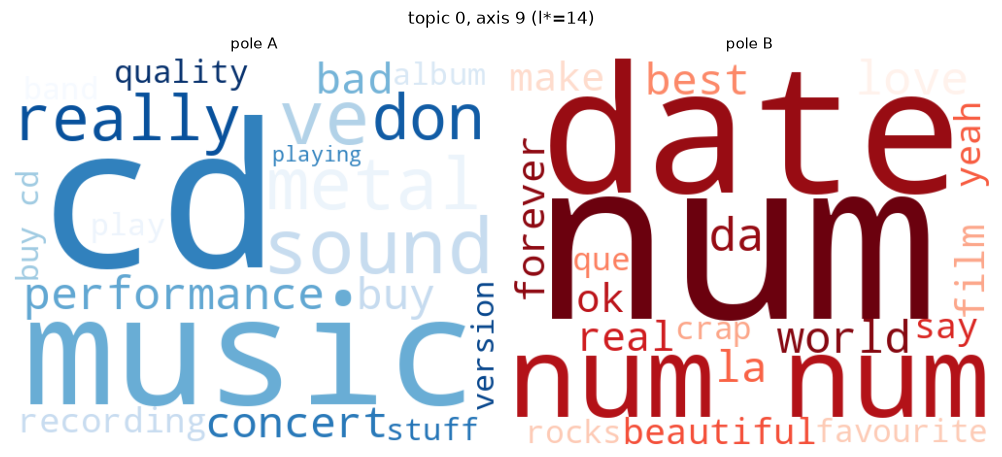

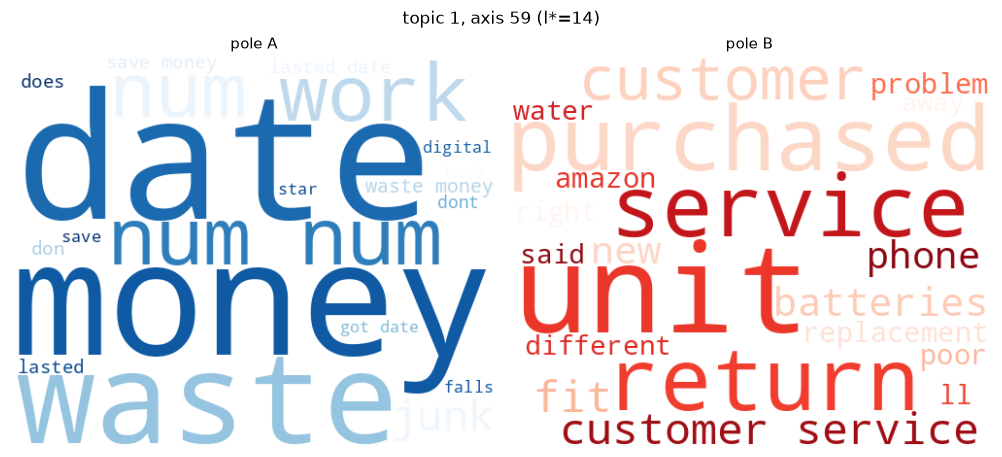

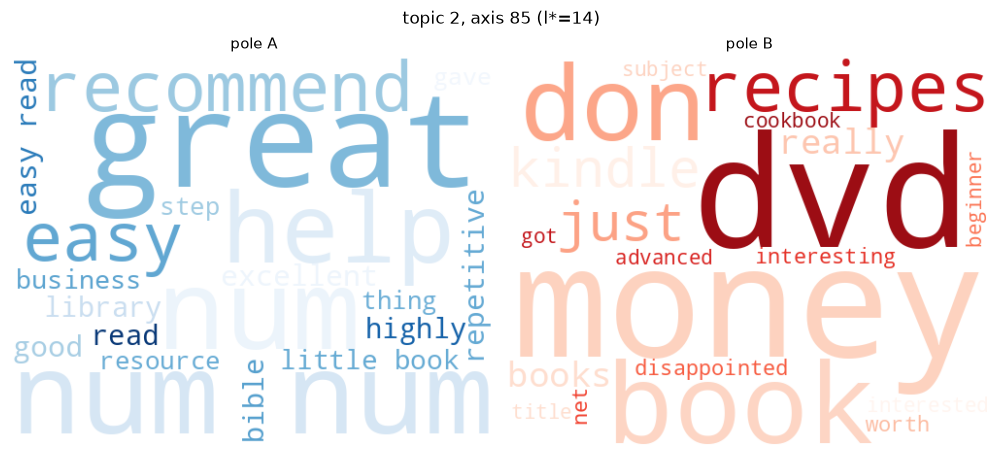

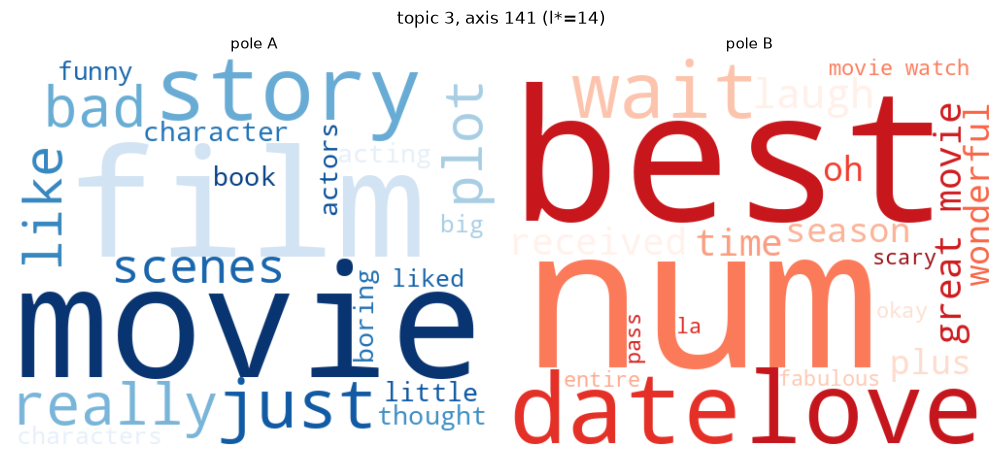

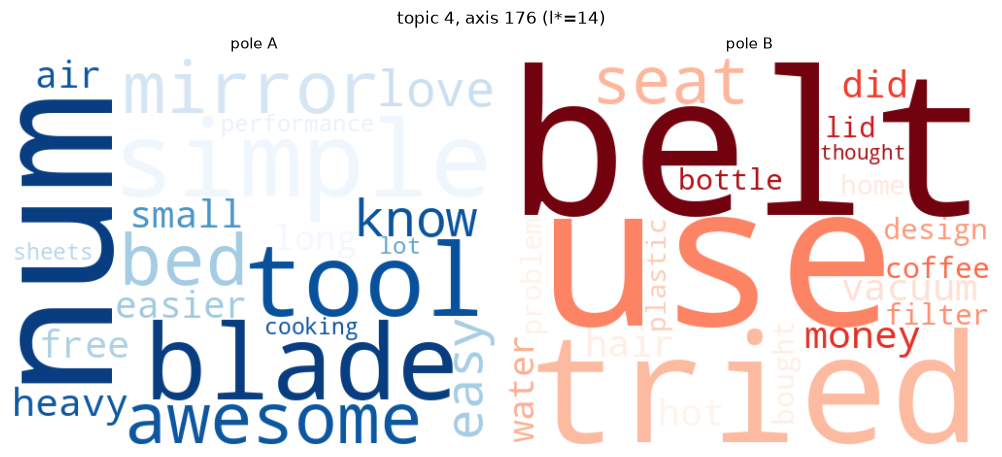

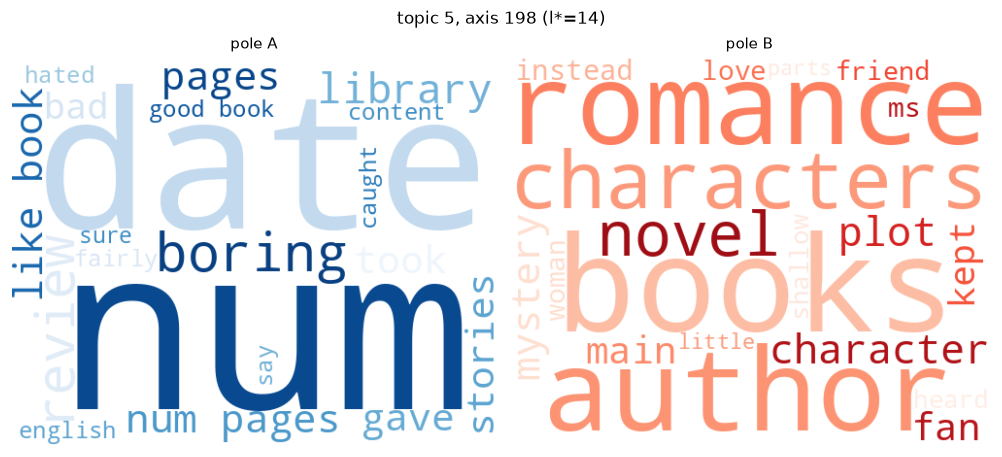

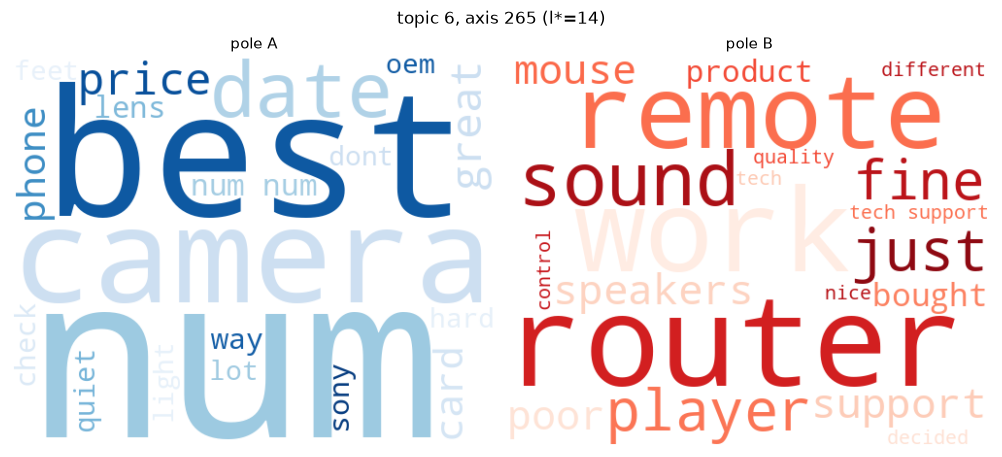

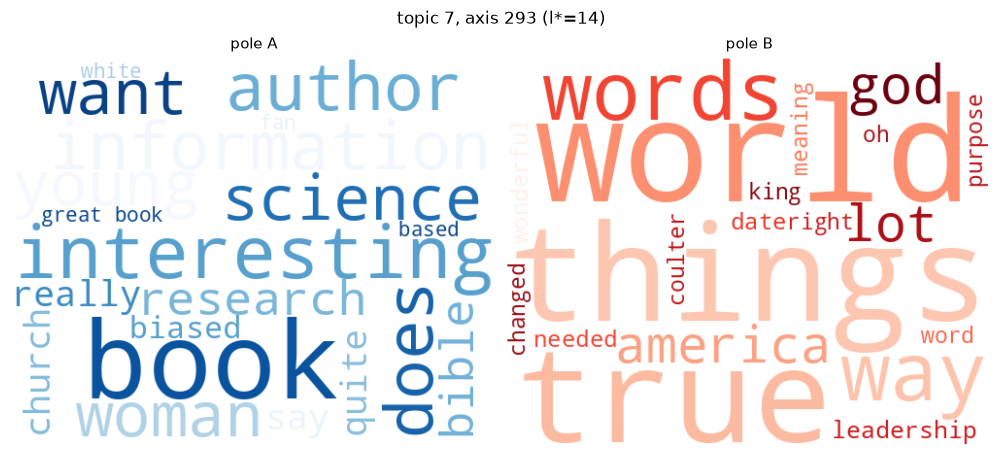

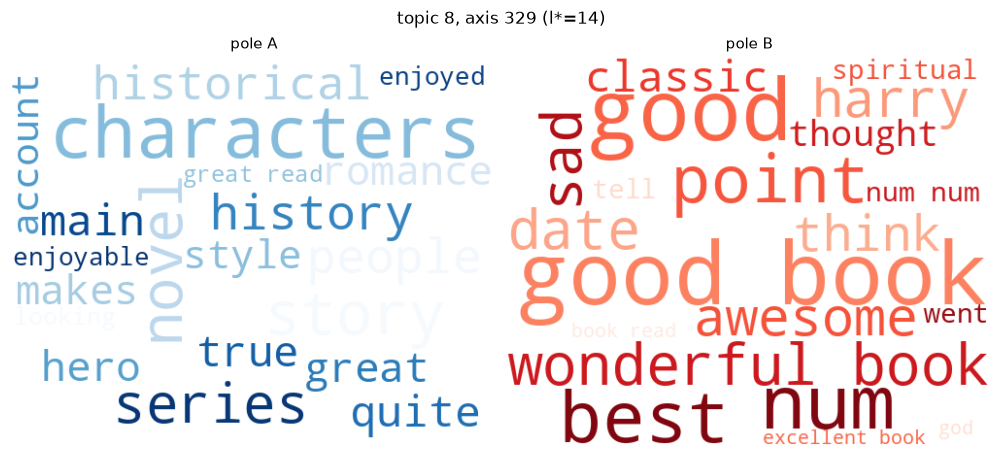

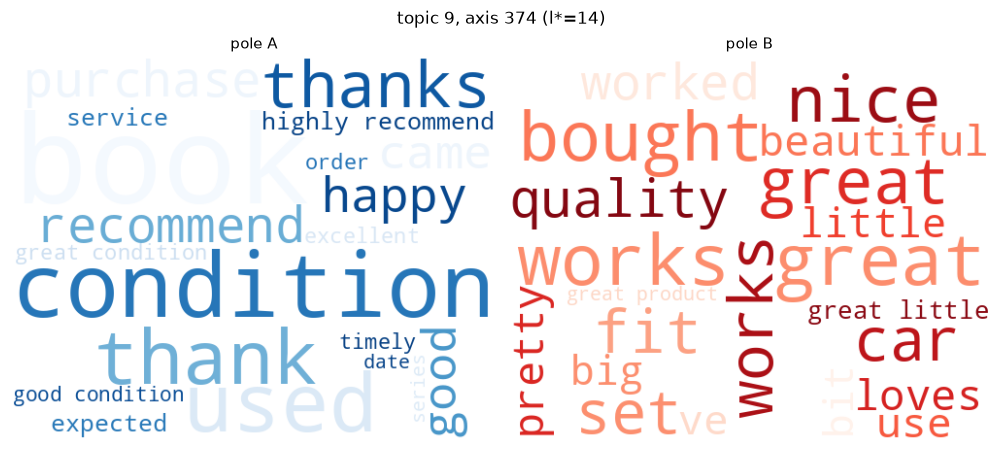

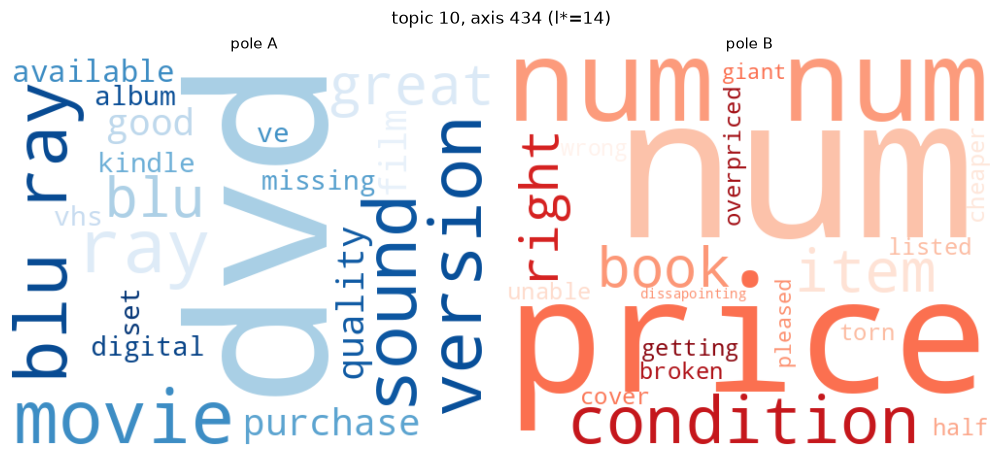

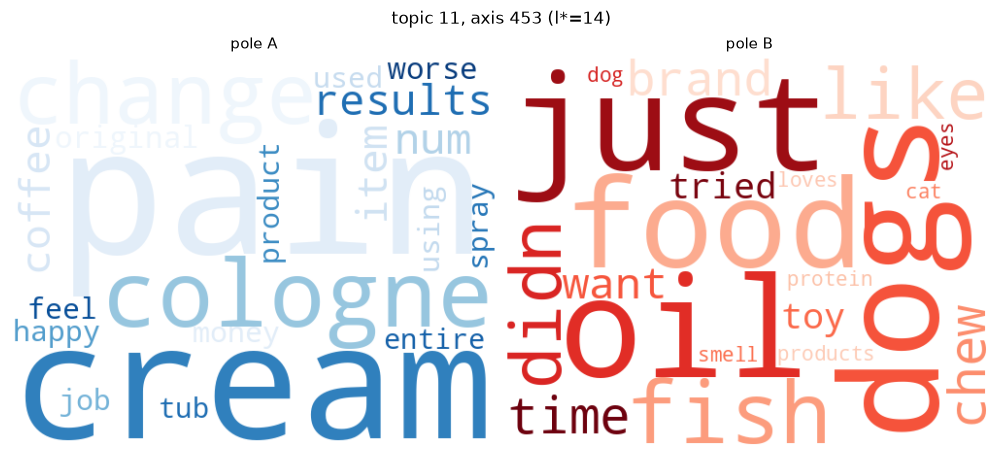

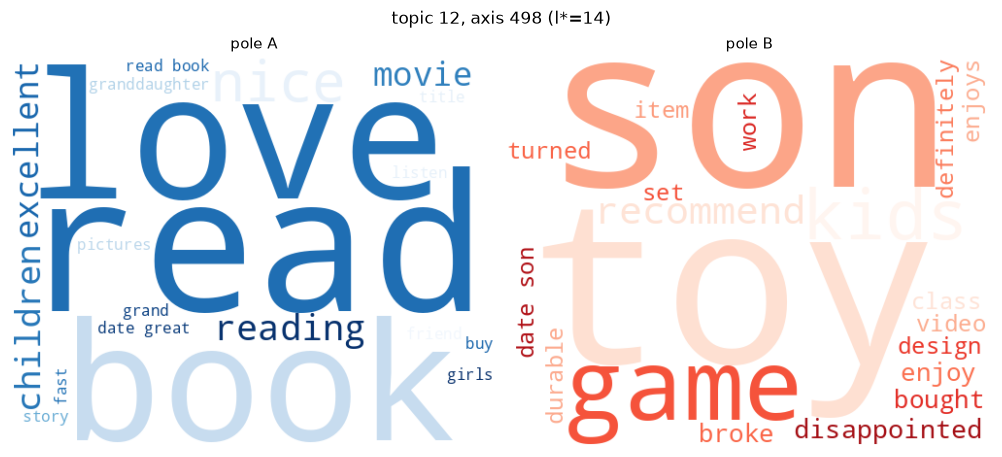

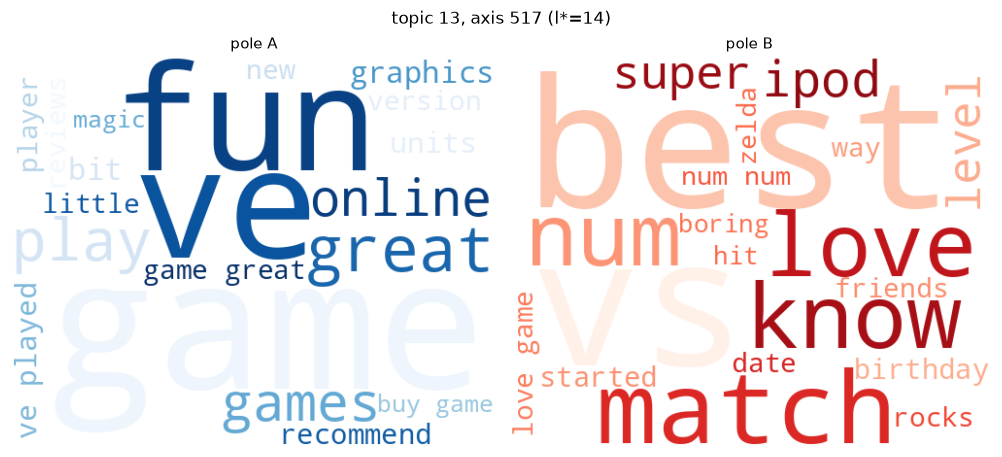

543 word-cloud pairs saved; 14 shown above as worked examples


In [10]:
wordcloud_names = [f"pv_wordcloud_axis{int(a):03d}" for a in tfidf_summary["axis_id"]]
worked_axis_per_topic = (tfidf_summary.sort_values("effect_size_at_lstar", ascending=False)
                         .groupby("topic").head(1)["axis_id"].tolist())

if have(store, *wordcloud_names):
    print("[cache] all word-cloud pairs already on disk, skipping regeneration")
else:
    for axis_id in tfidf_summary["axis_id"]:
        freqs_A = PV.term_frequencies_for_wordcloud(tfidf_long, axis_id, "A")
        freqs_B = PV.term_frequencies_for_wordcloud(tfidf_long, axis_id, "B")
        row = tfidf_summary[tfidf_summary["axis_id"] == axis_id].iloc[0]
        fig = V.plot_pole_wordclouds(freqs_A, freqs_B,
                                     title=f"topic {row['topic']}, axis {axis_id} (l*={row['l_star']})")
        if axis_id in worked_axis_per_topic:
            show_fig(store, f"pv_wordcloud_axis{int(axis_id):03d}", fig)
        else:
            store.save_fig(f"pv_wordcloud_axis{int(axis_id):03d}", fig)
            plt.close(fig)
    print(f"{len(tfidf_summary)} word-cloud pairs saved; {len(worked_axis_per_topic)} shown above as worked examples")


## 5 - Gemma natural-language pole explanations

*Script equivalent: `10_pole_llm_explanations.py`. Saves to:
`tables/topol_pv_llm_explanations.csv`.*

`gemma-3-4b-pt` is the base/pretrained checkpoint already loaded as this
pipeline's `backend` -- it will happily CONTINUE text but won't reliably
OBEY an instruction like "explain the difference". So the prompt built by
`pole_llm.build_pole_prompt` is a grounded completion: a few real review
excerpts from pole A, a few from pole B (plus each axis's own top TF-IDF
words as an anchor), ending mid-sentence for the model to finish -- the same
"ground it in real corpus text rather than trust free generation" philosophy
`nla.pole_prototypes_table`'s `nearest_real_docs` already uses.

Loading the gemma backend is the heavy step here (GPU, ~4B params) -- done
lazily, only for this part.

In [ ]:
#!kill 167622

In [16]:
!nvidia-smi

Tue Jul 28 12:25:43 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.71.05              Driver Version: 595.71.05      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-PCIE-40GB          On  |   00000000:C1:00.0 Off |                    0 |
| N/A   27C    P0             34W /  250W |    5127MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [17]:
import gc
gc.collect(); torch.cuda.empty_cache()
print("loading gemma-3-4b-pt backend (same checkpoint used throughout this pipeline)...")
backend = make_backend(cfg)
print("model:", cfg.model.name, "| d_model", backend.d_model)


loading gemma-3-4b-pt backend (same checkpoint used throughout this pipeline)...


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

model: /home/users/g/gomeztei/scratch/hf_cache/models--google--gemma-3-4b-pt/snapshots/cc012e0a6d0787b4adcc0fa2c4da74402494554d | d_model 2560


In [18]:
import os, sys, warnings, gc
warnings.filterwarnings("ignore")
import pandas as pd
import torch


def find_repo_root(start):
    p = os.path.abspath(start)
    for _ in range(6):
        if os.path.isdir(os.path.join(p, "topolm")):
            return p
        if os.path.isdir(os.path.join(p, "scr", "topolm")):
            return os.path.join(p, "scr")
        p = os.path.dirname(p)
    return None


REPO_ROOT = find_repo_root(os.getcwd())
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

from topolm.config import Config
from topolm.store import RunStore
from topolm.backends import make_backend
from topolm import topol_activations as TA, nla as NLA, pole_llm as PL


def have(store, *names):
    return all(n in store.manifest["entries"] for n in names)


def load_table(store, name):
    return pd.read_csv(os.path.join(store.dir, store.manifest["entries"][name]["path"]))


runs_dir = os.path.join(REPO_ROOT, "runs")
store = RunStore(runs_dir, "amazon_reviews", tag="pipeline_2", resume=True)
cfg = Config.from_dict(store.load_json("config"))

texts = store.load_object("texts")
cluster_labels = store.load_array("cluster_labels").astype(int)
gate_results = store.load_object("topol_gate_results")
cache = TA.load_activation_cache(store)
vocab = store.load_object("topol_nla_vocab")

print("rebuilding the per-axis document dataset (prepare_axis_dataset, cheap/CPU)...")
data, axis_index = NLA.prepare_axis_dataset(gate_results, texts, cluster_labels, cache, vocab, max_len=48)
print(f"{len(axis_index)} gate-passing axes across {axis_index['topic'].nunique()} topics")

tfidf_summary = load_table(store, "topol_pv_tfidf_summary") if have(store, "topol_pv_tfidf_summary") else None
if tfidf_summary is None:
    print("WARNING: topol_pv_tfidf_summary not found on disk -- explanations will fall back to snippets only")

gc.collect(); torch.cuda.empty_cache()
print("loading gemma-3-4b-pt backend...")
backend = make_backend(cfg)
print("model:", cfg.model.name, "| d_model", backend.d_model)


rebuilding the per-axis document dataset (prepare_axis_dataset, cheap/CPU)...
543 gate-passing axes across 14 topics
loading gemma-3-4b-pt backend...


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

model: /home/users/g/gomeztei/scratch/hf_cache/models--google--gemma-3-4b-pt/snapshots/cc012e0a6d0787b4adcc0fa2c4da74402494554d | d_model 2560


In [19]:
if have(store, "topol_pv_llm_explanations"):
    print("[cache] topol_pv_llm_explanations found on disk, loading")
    llm_explanations = load_table(store, "topol_pv_llm_explanations")
else:
    llm_explanations = PL.explain_axes(backend, data, axis_index, tfidf_summary=tfidf_summary,
                                       n_snippets=4, max_new_tokens=50, batch_size=4,
                                       random_state=cfg.random_state)
    store.save_table("topol_pv_llm_explanations", llm_explanations)

print(f"{len(llm_explanations)} axes explained")
display(llm_explanations.head(10))


543 axes explained


,axis_id,topic,contrast_index,explanation
0,0,0,1,"Group A reviews are more likely to use the word ""num"" and Group B reviews are more likely to use..."
1,1,0,2,Group A reviews are more positive than Group B reviews.
2,2,0,3,Group A reviews are more negative than Group B reviews.
3,3,0,4,Group A reviews are more negative and Group B reviews are more positive.
4,4,0,5,Group A reviews are more positive than Group B reviews.
5,5,0,6,Group A reviews are more positive than Group B reviews.
6,6,0,7,"Group A reviews are more likely to use the word ""music"" and Group B reviews are more likely to u..."
7,7,0,8,Group A reviews are more negative and Group B reviews are more positive.
8,8,0,9,Group A reviews are more positive and Group B reviews are more negative.
9,9,0,10,Group A reviews are more negative and Group B reviews are more positive.


### Worked examples: reading the explanation next to the TF-IDF words

Cross-checking the LLM's gloss against the independently-computed TF-IDF
terms for the same axes -- they should tell a consistent story (same
"read the reviews, read the decoded words, check they agree" check Part 1's
notebook applies to the NLA decoder).

In [20]:
import os, sys
import pandas as pd

def find_repo_root(start):
    p = os.path.abspath(start)
    for _ in range(6):
        if os.path.isdir(os.path.join(p, "topolm")):
            return p
        if os.path.isdir(os.path.join(p, "scr", "topolm")):
            return os.path.join(p, "scr")
        p = os.path.dirname(p)
    return None

REPO_ROOT = find_repo_root(os.getcwd())
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

from topolm.store import RunStore
from IPython.display import display


def have(store, *names):
    return all(n in store.manifest["entries"] for n in names)


def load_table(store, name):
    return pd.read_csv(os.path.join(store.dir, store.manifest["entries"][name]["path"]))


runs_dir = os.path.join(REPO_ROOT, "runs")
store = RunStore(runs_dir, "amazon_reviews", tag="pipeline_2", resume=True)

llm_explanations = load_table(store, "topol_pv_llm_explanations")
tfidf_summary = load_table(store, "topol_pv_tfidf_summary")

# same derivation the word-cloud cell used: one representative (largest-effect-size) axis per topic
worked_axis_per_topic = (tfidf_summary.sort_values("effect_size_at_lstar", ascending=False)
                         .groupby("topic").head(1)["axis_id"].tolist())

print(f"{len(llm_explanations)} explanations, {len(tfidf_summary)} tfidf rows, "
      f"{len(worked_axis_per_topic)} worked axes loaded")


543 explanations, 543 tfidf rows, 14 worked axes loaded


In [21]:
worked = (llm_explanations.merge(
    tfidf_summary[["axis_id", "top_terms_A", "top_terms_B"]], on="axis_id", how="left")
    [llm_explanations["axis_id"].isin(worked_axis_per_topic)])
display(worked[["topic", "axis_id", "top_terms_A", "top_terms_B", "explanation"]])


,topic,axis_id,top_terms_A,top_terms_B,explanation
9,0,9,"cd, music, sound, ve, metal, really, don, performance, buy, concert, bad, recording, quality, ba...","num, date, num num, love, da, world, best, la, real, forever, make, film, ok, beautiful, say, ye...",Group A reviews are more negative and Group B reviews are more positive.
59,1,59,"date, money, waste, num num, work, num, junk, waste money, don, lasted, does, save money, lasted...","unit, purchased, return, service, customer, customer service, fit, batteries, new, phone, replac...",Group A reviews are more negative than Group B reviews.
85,2,85,"great, num num, num, help, recommend, easy, excellent, repetitive, good, easy read, library, hig...","money, dvd, book, don, recipes, kindle, just, really, books, disappointed, net, interesting, wor...",Group A reviews are more positive and Group B reviews are more negative.
141,3,141,"movie, film, story, just, really, bad, plot, like, scenes, character, boring, actors, acting, li...","num, best, love, date, wait, laugh, time, great movie, received, season, plus, oh, wonderful, mo...",Group A reviews are more positive than Group B reviews.
176,4,176,"num, simple, blade, tool, mirror, awesome, bed, know, easy, love, heavy, small, free, air, easie...","belt, use, tried, seat, money, vacuum, hair, hot, did, water, design, bottle, coffee, filter, bo...",Group A reviews are more positive than Group B reviews.
198,5,198,"num, date, boring, review, library, pages, num pages, like book, took, stories, gave, bad, good ...","books, romance, author, characters, novel, character, plot, mystery, main, fan, kept, instead, m...",Group A reviews are more positive than Group B reviews.
265,6,265,"num, best, camera, date, price, great, card, phone, num num, lens, way, sony, quiet, check, dont...","router, work, remote, sound, player, just, fine, speakers, support, mouse, poor, bought, product...",Group A reviews are more positive and Group B reviews are more negative.
293,7,293,"book, interesting, information, does, author, science, want, young, woman, research, bible, real...","world, things, true, words, way, god, america, lot, leadership, date, wonderful, needed, purpose...",Group A reviews are more positive and Group B reviews are more negative.
329,8,329,"characters, story, novel, series, people, history, historical, main, quite, true, hero, great, m...","good book, good, num, best, point, wonderful book, sad, date, awesome, harry, think, classic, th...",Group A reviews are more positive than Group B reviews.
374,9,374,"book, condition, used, thank, thanks, purchase, recommend, happy, good, came, highly recommend, ...","works great, bought, nice, great, works, fit, set, car, quality, worked, beautiful, loves, prett...",Group A reviews are more positive than Group B reviews.


## 5b - Comparison: gemma-3-4b-it (instruction-tuned) pole explanations

*Script equivalent: `15_pole_llm_it_explanations.py`. Saves to:
`tables/topol_pv_llm_explanations_it.csv`, `tables/topol_pv_llm_pt_vs_it.csv`.*

The worked examples above already show the `-pt` route's weak point: reading
`llm_explanations` against `topol_pv_tfidf_summary` for all 543 axes, **84.9%
of `-pt` glosses reduce to a generic "Group A/B reviews are more
positive/negative"** -- including for the majority of axes whose OWN TF-IDF
vocabulary is not about sentiment at all (e.g. an axis splitting religious
from political nonfiction, or computing peripherals from audio equipment; see
Part 3's worked topic). That is a real limitation of a non-instruction-tuned
4B base model asked to continue a completion, not evidence that the axes
lack real, nameable content -- the TF-IDF vocabulary already shows they don't.

This section asks the identical question, grounded in the identical evidence
(same snippets, same TF-IDF anchor words), of **`google/gemma-3-4b-it`** --
the instruction-tuned sibling checkpoint -- via a direct instruction
(`pole_llm.build_pole_prompt_it`/`explain_axes_it`) rather than a hanging
completion. This is a SECOND ~4B-parameter model resident on the GPU
alongside (or instead of, if VRAM is tight) the `-pt` field backend.

**How to read the result:** do not treat `-it` as simply "the correct
answer" -- an instruction-tuned model can produce a fluent, confident, but
WRONG contrast just as easily as a base model can default to a generic one.
The trustworthy signal is agreement across three independent routes (TF-IDF
vocabulary, `-pt` completion, `-it` instruction), not any single one. Compare
`topol_pv_llm_pt_vs_it`'s `explanation` (`-pt`) and `explanation_it` (`-it`)
columns against `top_terms_A`/`top_terms_B` for the same worked axes used
above, and note whether `-it`'s generic-sentiment-gloss rate (printed by the
script) is meaningfully lower than `-pt`'s 84.9%.

In [22]:
import glob as _glob
from huggingface_hub import snapshot_download
from topolm.config import ModelConfig
from topolm import pole_llm as PL

IT_MODEL = "google/gemma-3-4b-it"
hf_cache_dir = os.path.expanduser("~/scratch/hf_cache")


def find_local_snapshot(repo_id, cache_dir):
    folder_name = "models--" + repo_id.replace("/", "--")
    matches = _glob.glob(os.path.join(cache_dir, folder_name, "snapshots", "*"))
    return matches[0] if matches else None


if have(store, "topol_pv_llm_explanations_it"):
    print("[cache] topol_pv_llm_explanations_it found on disk, loading")
    explanations_it = load_table(store, "topol_pv_llm_explanations_it")
else:
    it_snapshot = find_local_snapshot(IT_MODEL, hf_cache_dir)
    if it_snapshot is None:
        print(f"{IT_MODEL} not found in {hf_cache_dir} -- downloading now (one-time)...")
        it_snapshot = snapshot_download(repo_id=IT_MODEL, cache_dir=hf_cache_dir)

    # free the -pt backend's VRAM first if this GPU is memory-constrained for two 4B models
    # del backend; gc.collect(); torch.cuda.empty_cache()

    it_cfg = Config.from_dict(store.load_json("config"))
    it_cfg.model = ModelConfig(name=it_snapshot, layer=it_cfg.model.layer, pooling=it_cfg.model.pooling,
                               dtype=it_cfg.model.dtype, device=it_cfg.model.device,
                               max_length=it_cfg.model.max_length, batch_size=it_cfg.model.batch_size)
    print(f"loading {IT_MODEL}...")
    backend_it = make_backend(it_cfg)
    print("model:", IT_MODEL, "| d_model", backend_it.d_model)

    explanations_it = PL.explain_axes_it(backend_it, data, axis_index, tfidf_summary=tfidf_summary,
                                         n_snippets=4, max_new_tokens=80, batch_size=4,
                                         random_state=cfg.random_state)
    store.save_table("topol_pv_llm_explanations_it", explanations_it)

print(f"{len(explanations_it)} axes explained by -it")
display(explanations_it.head(10))


google/gemma-3-4b-it not found in /home/users/g/gomeztei/scratch/hf_cache -- downloading now (one-time)...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

loading google/gemma-3-4b-it...


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

model: google/gemma-3-4b-it | d_model 2560
543 axes explained by -it


,axis_id,topic,contrast_index,explanation_it
0,0,0,1,"Group A reviews focus on rock music and bands, specifically discussing production quality and no..."
1,1,0,2,"The primary contrast lies in the subject matter: Group A reviews music by a singer (Beth Hart), ..."
2,2,0,3,Group A reviews primarily critique the *quality* and *originality* of specific musical albums an...
3,3,0,4,The two groups of reviews discuss fundamentally different subjects: Group A reviews music albums...
4,4,0,5,"Group A reviews primarily focus on discussing the *history, critical reception, and artistic mer..."
5,5,0,6,"The reviews in Group A primarily focus on musical style and comparisons to established artists, ..."
6,6,0,7,The primary contrast lies in the subject matter: Group A reviews primarily focus on musical arti...
7,7,0,8,"The reviews in Group A primarily focus on the musical qualities and artistic merit of albums, wh..."
8,8,0,9,"Group A reviews primarily focus on musical albums and artists, discussing their sound, quality, ..."
9,9,0,10,"Group A reviews primarily critique the *quality* and *musical merit* of the albums themselves, f..."


In [23]:
# side-by-side: TF-IDF vocabulary, -pt gloss, -it gloss, for the same worked axes Part 5 used
pt_vs_it = (explanations_it.merge(llm_explanations[["axis_id", "explanation"]], on="axis_id", how="left")
                          .merge(tfidf_summary[["axis_id", "top_terms_A", "top_terms_B"]], on="axis_id", how="left"))
store.save_table("topol_pv_llm_pt_vs_it", pt_vs_it)

generic_pt = pt_vs_it["explanation"].str.contains("positive|negative", case=False, na=False)
generic_it = (pt_vs_it["explanation_it"].str.contains("positive|negative", case=False, na=False)
             & (pt_vs_it["explanation_it"].str.len() < 90))
print(f"-pt generic-sentiment-gloss rate: {generic_pt.mean():.1%}")
print(f"-it generic-sentiment-gloss rate: {generic_it.mean():.1%}")
print()
display(pt_vs_it[pt_vs_it["axis_id"].isin(worked_axis_per_topic)]
        [["topic", "axis_id", "top_terms_A", "top_terms_B", "explanation", "explanation_it"]])


-pt generic-sentiment-gloss rate: 84.9%
-it generic-sentiment-gloss rate: 0.0%



,topic,axis_id,top_terms_A,top_terms_B,explanation,explanation_it
9,0,9,"cd, music, sound, ve, metal, really, don, performance, buy, concert, bad, recording, quality, ba...","num, date, num num, love, da, world, best, la, real, forever, make, film, ok, beautiful, say, ye...",Group A reviews are more negative and Group B reviews are more positive.,"Group A reviews primarily critique the *quality* and *musical merit* of the albums themselves, f..."
59,1,59,"date, money, waste, num num, work, num, junk, waste money, don, lasted, does, save money, lasted...","unit, purchased, return, service, customer, customer service, fit, batteries, new, phone, replac...",Group A reviews are more negative than Group B reviews.,"Group A reviews primarily focus on product defects, disappointment with quality, and negative ex..."
85,2,85,"great, num num, num, help, recommend, easy, excellent, repetitive, good, easy read, library, hig...","money, dvd, book, don, recipes, kindle, just, really, books, disappointed, net, interesting, wor...",Group A reviews are more positive and Group B reviews are more negative.,The primary contrast lies in the subject matter: Group A reviews focus on a technical textbook (...
141,3,141,"movie, film, story, just, really, bad, plot, like, scenes, character, boring, actors, acting, li...","num, best, love, date, wait, laugh, time, great movie, received, season, plus, oh, wonderful, mo...",Group A reviews are more positive than Group B reviews.,The reviews in Group A primarily focus on the quality and specific aspects of individual films (...
176,4,176,"num, simple, blade, tool, mirror, awesome, bed, know, easy, love, heavy, small, free, air, easie...","belt, use, tried, seat, money, vacuum, hair, hot, did, water, design, bottle, coffee, filter, bo...",Group A reviews are more positive than Group B reviews.,Group A reviews focus on the shortcomings and limitations of portable electronic devices (a fan ...
198,5,198,"num, date, boring, review, library, pages, num pages, like book, took, stories, gave, bad, good ...","books, romance, author, characters, novel, character, plot, mystery, main, fan, kept, instead, m...",Group A reviews are more positive than Group B reviews.,The reviews in Group A primarily focus on the narrative content and individual stories within a ...
265,6,265,"num, best, camera, date, price, great, card, phone, num num, lens, way, sony, quiet, check, dont...","router, work, remote, sound, player, just, fine, speakers, support, mouse, poor, bought, product...",Group A reviews are more positive and Group B reviews are more negative.,"Group A reviews predominantly focus on specific hardware products like cameras, disks, and audio..."
293,7,293,"book, interesting, information, does, author, science, want, young, woman, research, bible, real...","world, things, true, words, way, god, america, lot, leadership, date, wonderful, needed, purpose...",Group A reviews are more positive and Group B reviews are more negative.,The primary difference between Group A and Group B reviews lies in their subject matter: Group A...
329,8,329,"characters, story, novel, series, people, history, historical, main, quite, true, hero, great, m...","good book, good, num, best, point, wonderful book, sad, date, awesome, harry, think, classic, th...",Group A reviews are more positive than Group B reviews.,Group A reviews primarily focus on the quality of the *content* and narrative elements of the wo...
374,9,374,"book, condition, used, thank, thanks, purchase, recommend, happy, good, came, highly recommend, ...","works great, bought, nice, great, works, fit, set, car, quality, worked, beautiful, loves, prett...",Group A reviews are more positive than Group B reviews.,Group A reviews predominantly discuss the reliability and satisfaction with a range of ordered p...


## 6 - Per-topic polar fields

*Script equivalent: `11_topic_fields.py`. Saves to:
`figures/pv_topic_field_{topic}.*` (one relations+compass pair per topic).*

Same pooled, cross-topic ensemble Part 1 already assembled
(`field.pooled_field_assembly`), subset by topic and re-plotted with the
SAME `viz.plot_vector_relations`/`plot_vector_compass` (they only need a
`(k, d)` matrix + ids -- no new plotting code) -- each topic's own field,
readable on its own terms, alongside the existing pooled view for
comparison.

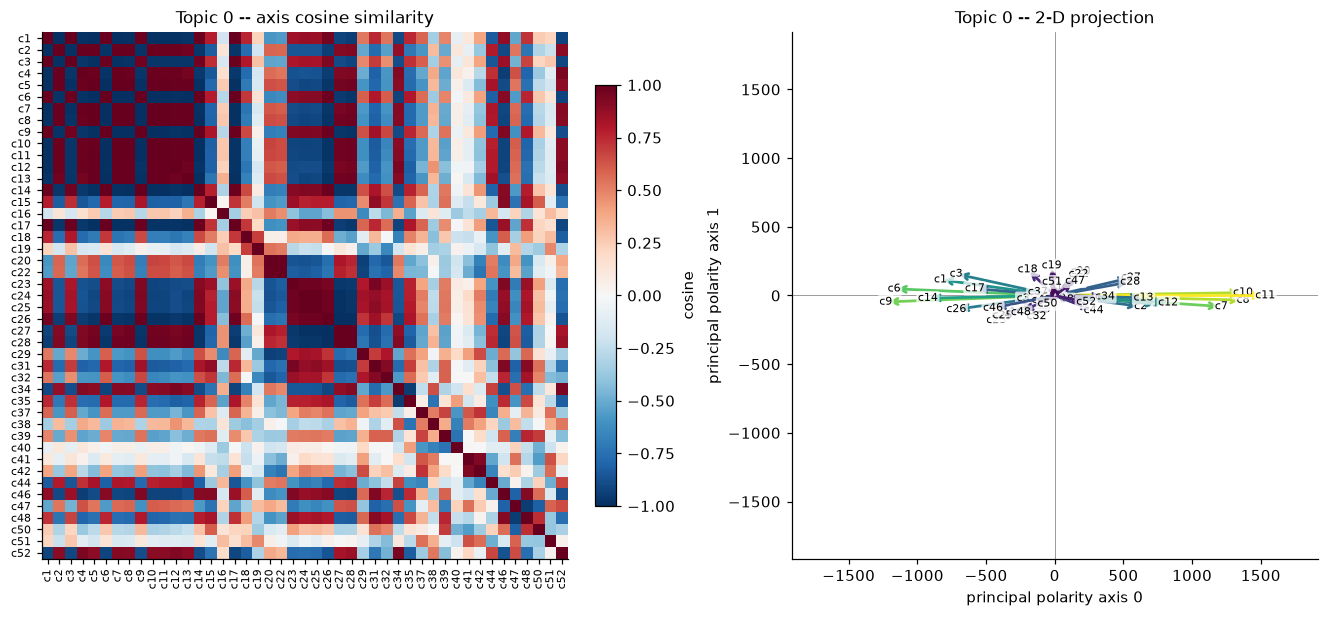

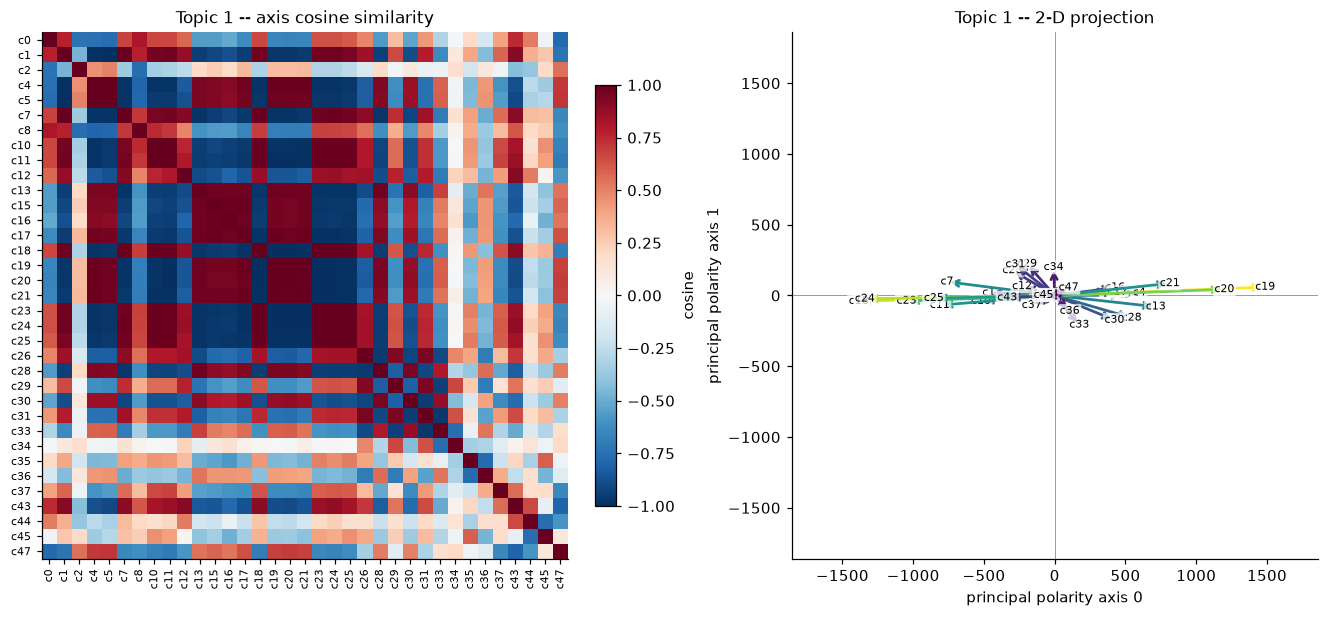

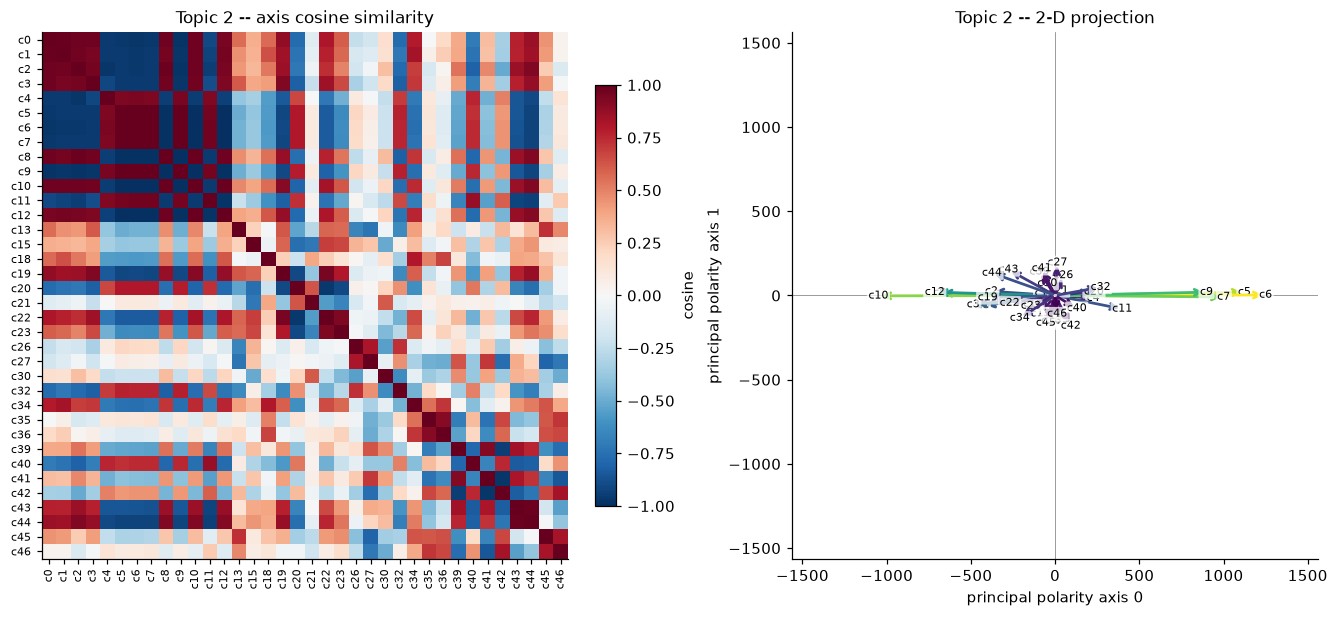

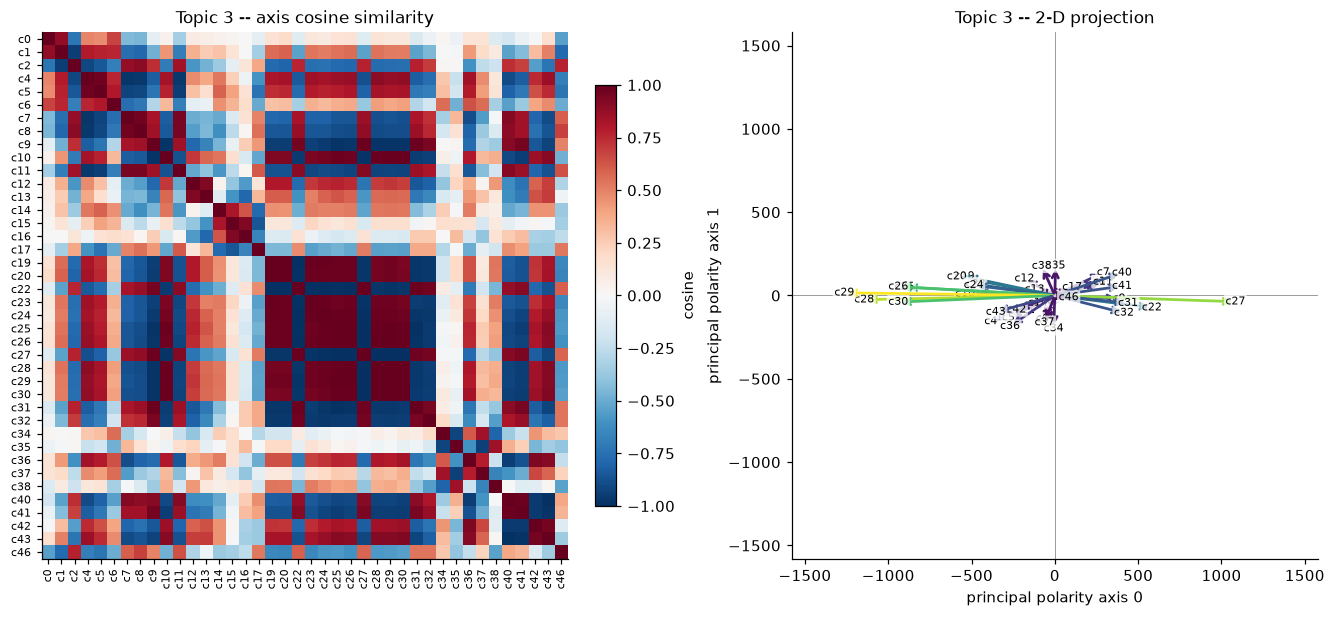

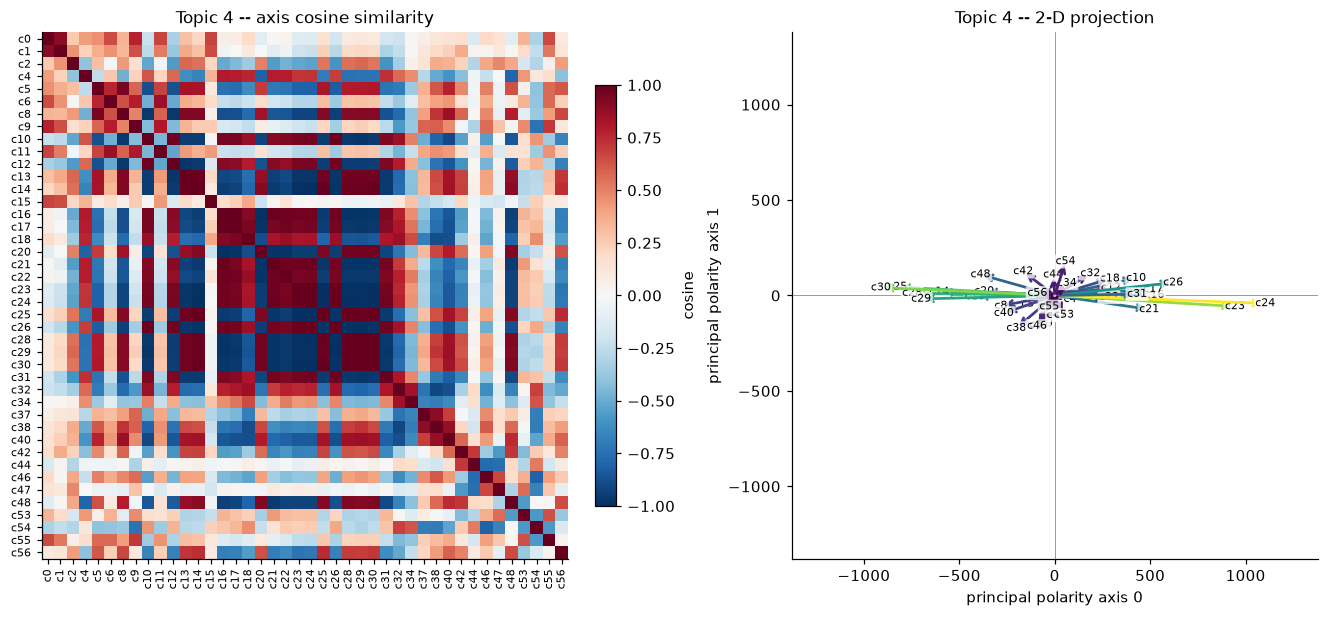

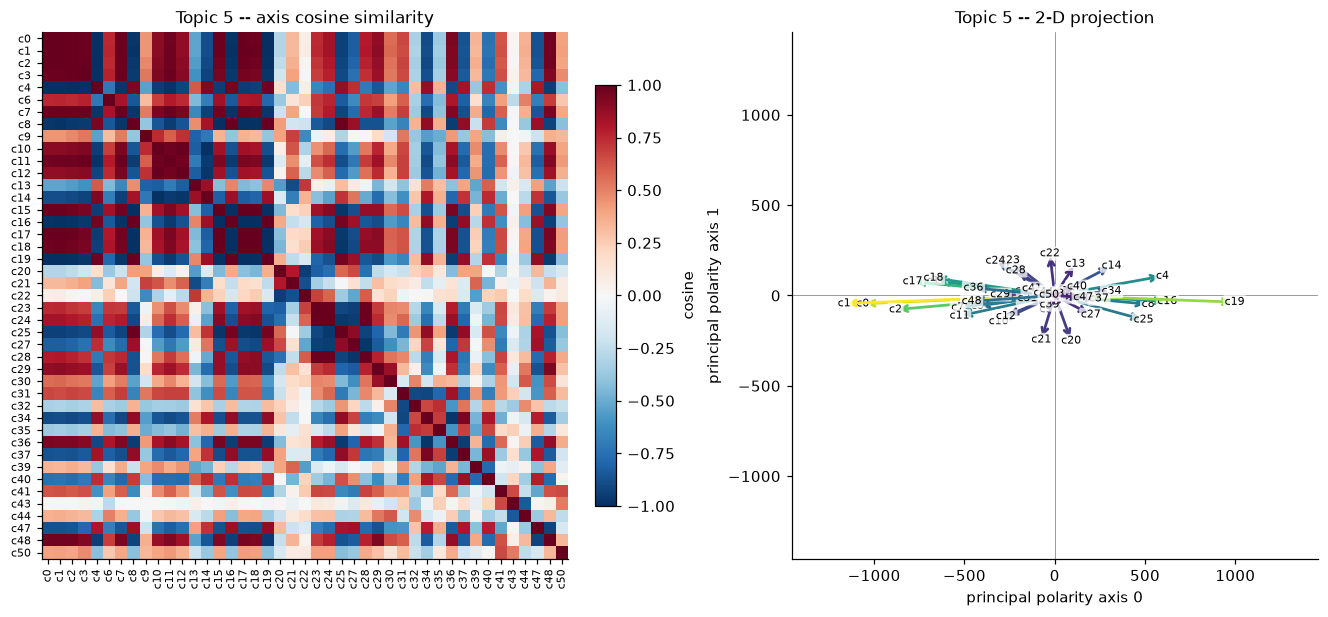

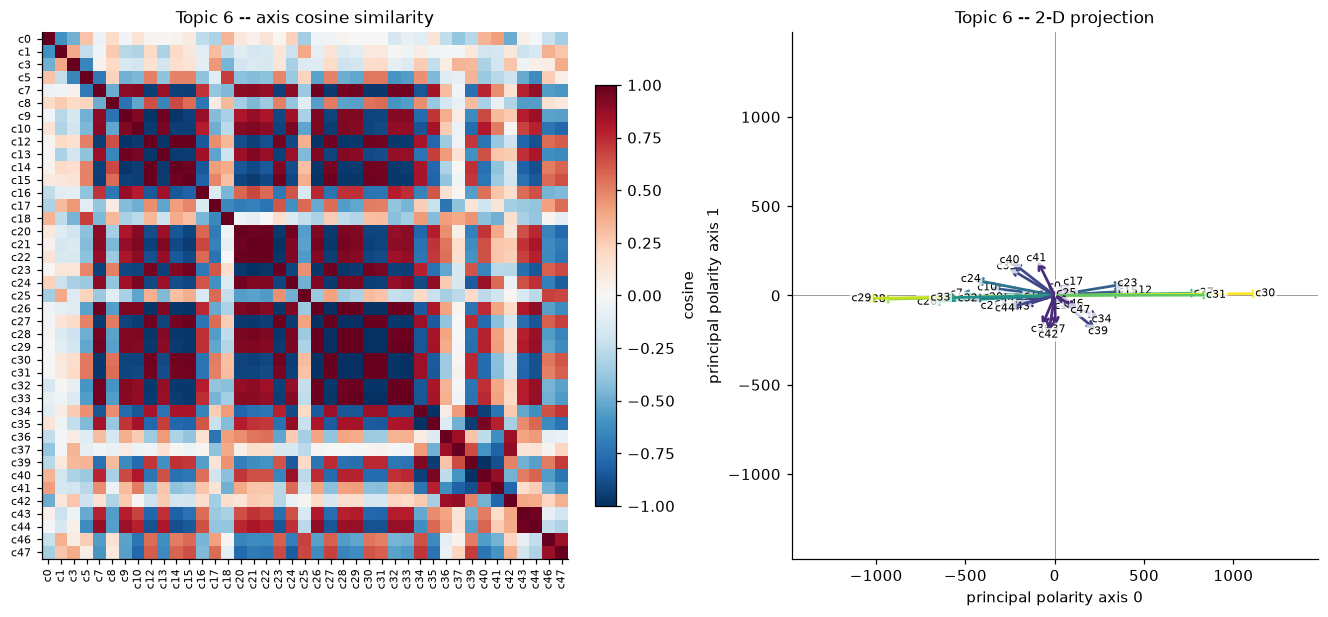

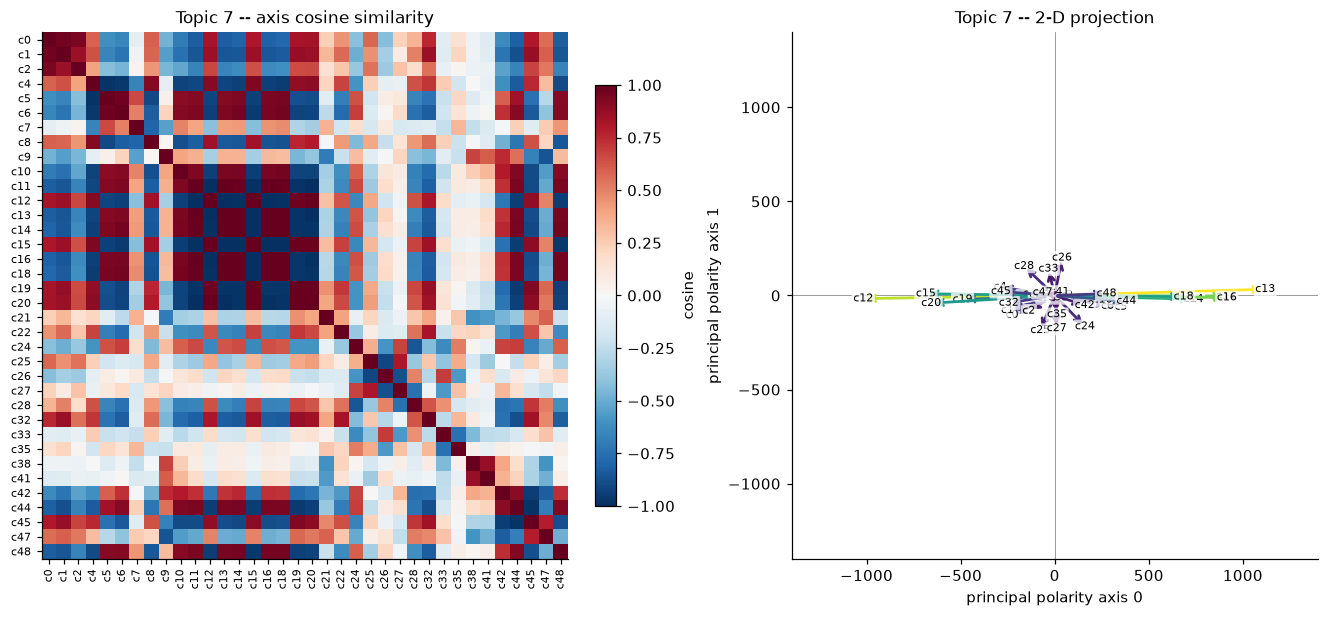

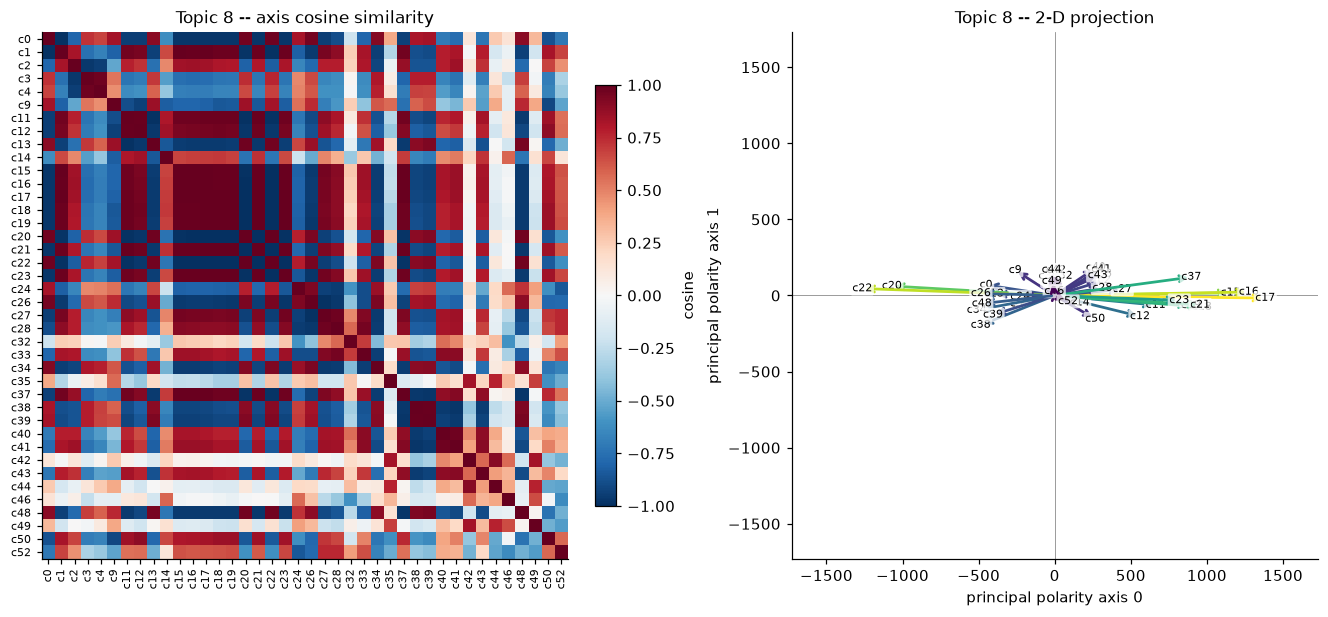

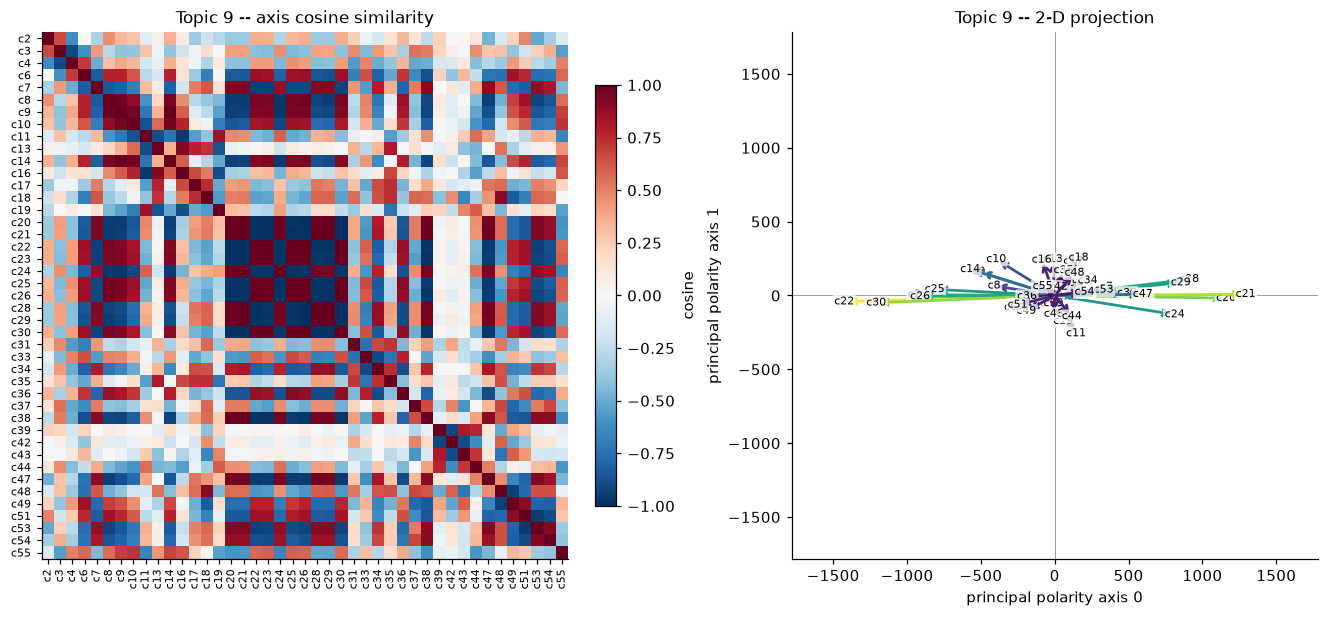

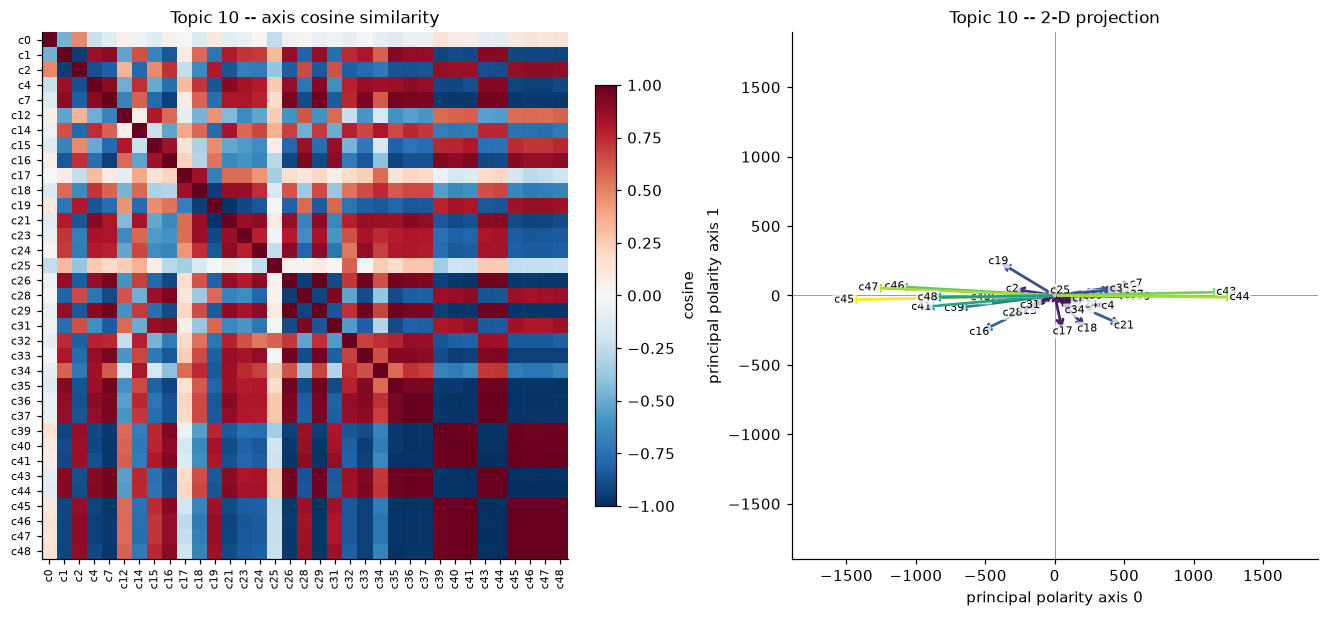

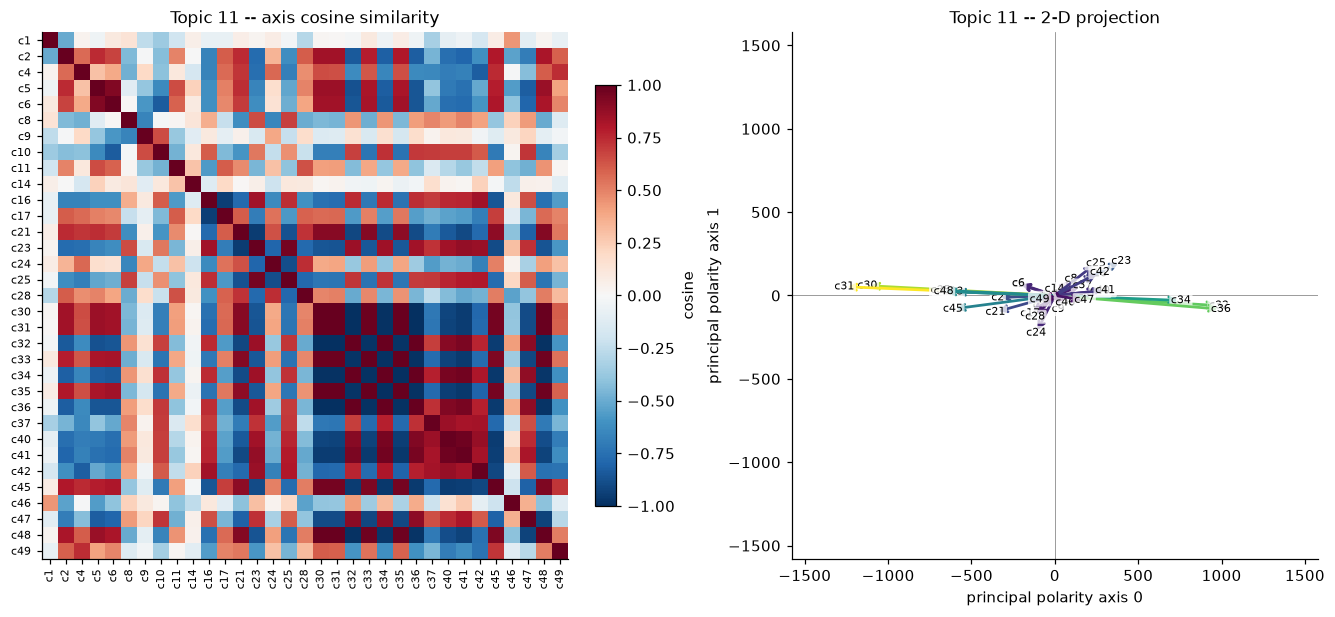

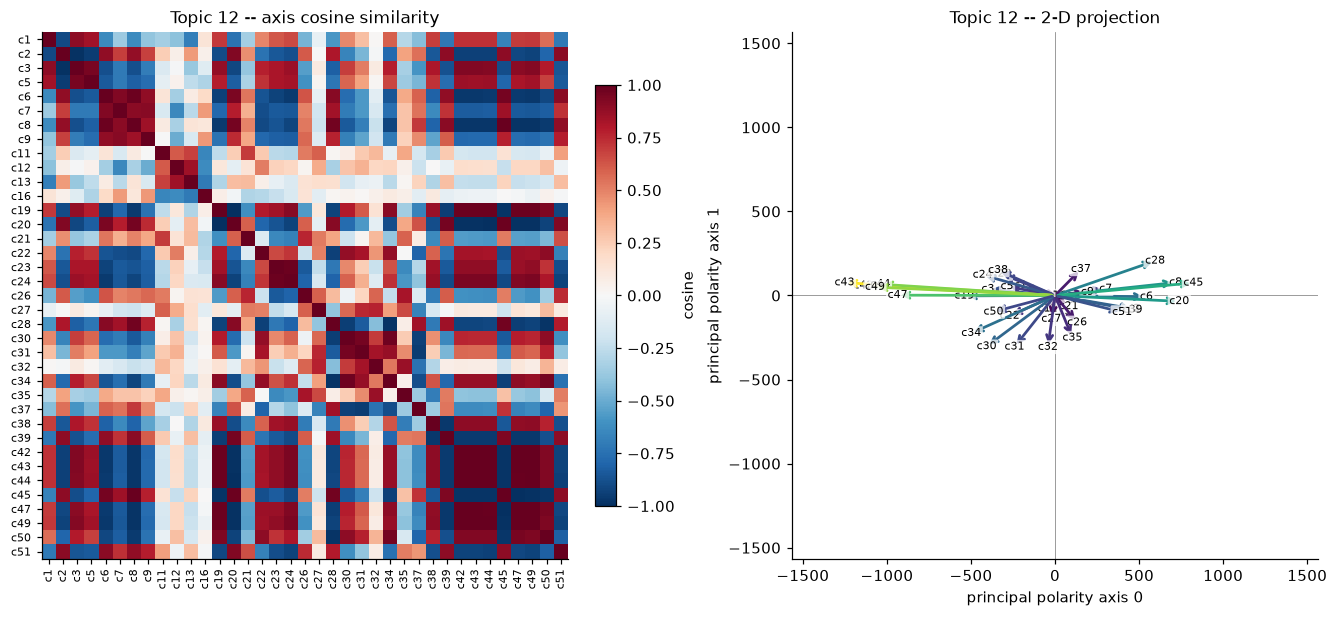

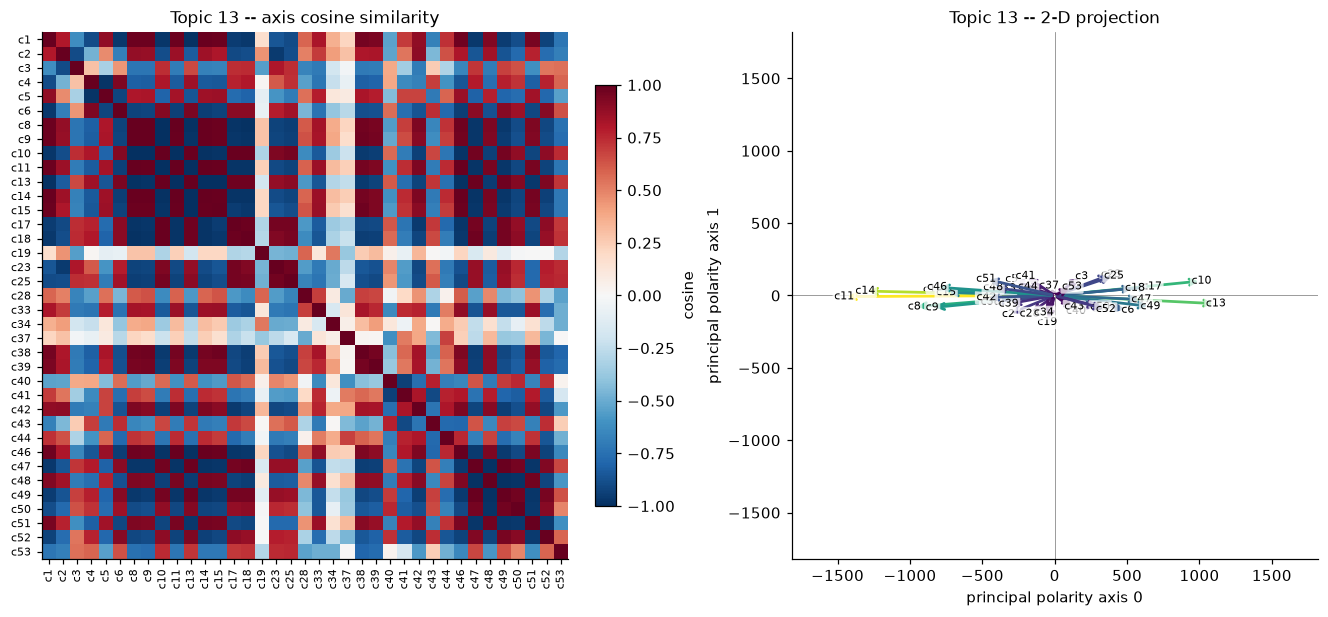

In [24]:
pooled = F.pooled_field_assembly(gate_results, ref_layer, cache["layers"])
topic_ids_pooled = np.asarray(pooled["topic_ids"])
contrast_ids_pooled = np.asarray(pooled["contrast_ids"])

topic_field_names = [f"pv_topic_field_{t}" for t in sorted(set(topic_ids_pooled.tolist()))]
if have(store, *topic_field_names):
    print("[cache] all per-topic field figures already on disk -- re-plotting inline from the pooled ensemble anyway")

for t in sorted(set(topic_ids_pooled.tolist())):
    mask = topic_ids_pooled == t
    if mask.sum() < 2:
        print(f"topic {t}: only {mask.sum()} gate-passing axis(es) -- need >= 2 to plot, skipping")
        continue
    Vt = pooled["V"][mask]
    ids_t = [f"c{c}" for c in contrast_ids_pooled[mask]]
    axes2d, _ = DIM.principal_axes(Vt, n_axes=2, center=False)

    fig, axs = plt.subplots(1, 2, figsize=(12, 5.5), layout="constrained")
    V.plot_vector_relations(Vt, ids_t, ax=axs[0], title=f"Topic {t} -- axis cosine similarity")
    V.plot_vector_compass(Vt, ids_t, axes2d, ax=axs[1], title=f"Topic {t} -- 2-D projection")
    show_fig(store, f"pv_topic_field_{t}", fig)


### For comparison: the existing pooled, all-topics view

Re-displayed (not re-saved -- it already exists as `figures/19_pooled_field_of_axes`
from Part 1) so the per-topic views above can be read against the full,
cross-topic picture.

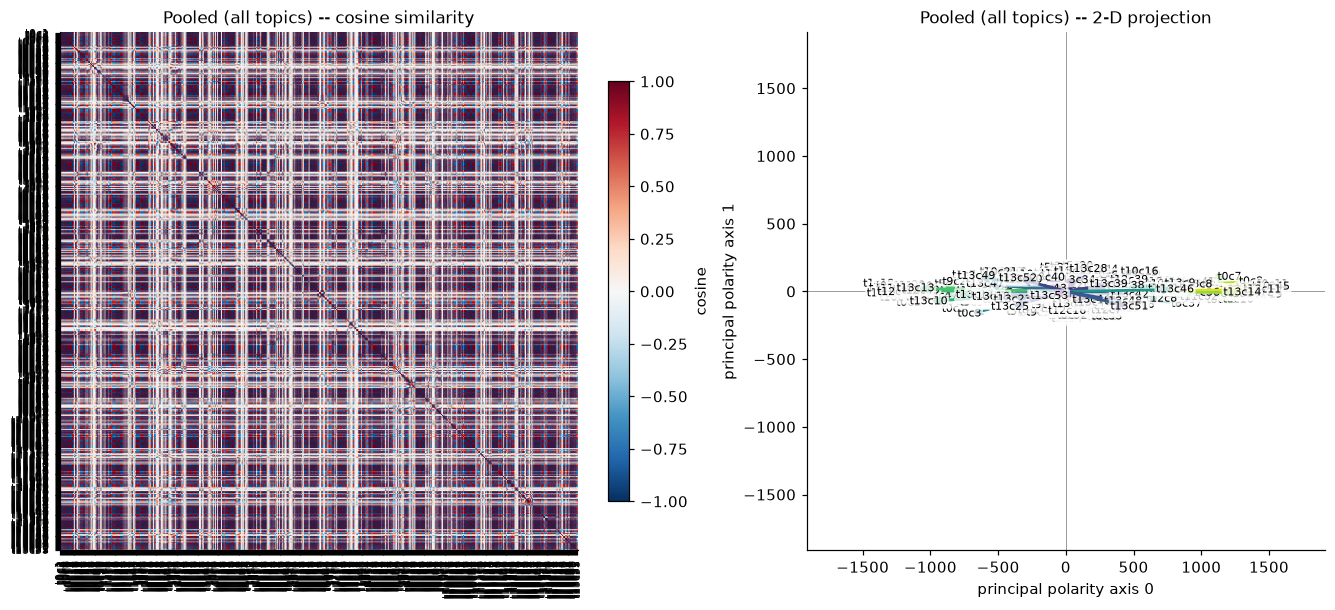

In [25]:
if pooled["k"] >= 2:
    axes2d_all, _ = DIM.principal_axes(pooled["V"], n_axes=2, center=False)
    axis_ids_pooled = [f"t{t}c{c}" for t, c in zip(topic_ids_pooled, contrast_ids_pooled)]
    fig, axs = plt.subplots(1, 2, figsize=(12, 5.5), layout="constrained")
    V.plot_vector_relations(pooled["V"], axis_ids_pooled, ax=axs[0], title="Pooled (all topics) -- cosine similarity")
    V.plot_vector_compass(pooled["V"], axis_ids_pooled, axes2d_all, ax=axs[1], title="Pooled (all topics) -- 2-D projection")
    display(fig)
    plt.close(fig)


## 7 - Closing the loop: does direction predict sentiment alignment?

*Script equivalent: `12_pole_sentiment_alignment.py`. Saves to:
`objects/topol_doc_sentiment.npz`, `tables/topol_pv_sentiment_alignment.csv`,
`objects/topol_pv_alignment_test.json`.*

**Hypothesis under test:** a polar vector's direction alone carries
information about its meaning -- specifically, an axis whose direction is
MORE similar to $v_{CB}^t$ (the human-coded sentiment reference for that
topic) should also be MORE sentiment-aligned by independent measures.

Two independent sentiment-alignment estimates, both compared against
`|cos(axis, v_CB^t)|`:

1. `corr_rating` -- ALREADY computed for every gate-passing axis back in
   `06_topol_discovery.py` (Pearson corr of the axis's own projection with
   the continuous Amazon star rating). Reused here, not recomputed.
2. `sentiment_delta` -- NEW: `cardiffnlp/twitter-roberta-base-sentiment-latest`
   scores every document once (continuous polarity = softmax(logits),
   `p_pos - p_neg`); each axis's `sentiment_delta` is
   mean(polarity | pole B) - mean(polarity | pole A).

$v_{CB}^t$ is recomputed via `topol_axes.depth_profile` at the exact same
`ref_layer` used for the pooled axis ensemble -- the SAME method
`pipeline.step_topol_baseline_compare` already uses for its own
`identification_cos`, reused here rather than reinvented, so cosine
similarity is measured on the same footing.

In [26]:
if have(store, "topol_doc_sentiment"):
    print("[cache] topol_doc_sentiment found on disk, loading")
    doc_sentiment = store.load_array("topol_doc_sentiment")
else:
    sentiment_model_name = "cardiffnlp/twitter-roberta-base-sentiment-latest"
    print(f"scoring {len(texts)} documents with {sentiment_model_name} (one pass over the whole corpus)...")
    tokenizer, sentiment_model, device = PS.load_sentiment_model(sentiment_model_name)
    doc_sentiment = PS.polarity_scalar(tokenizer, sentiment_model, texts, device, batch_size=32)
    store.save_array("topol_doc_sentiment", doc_sentiment, meta={"model": sentiment_model_name})

print(f"doc_sentiment: mean={doc_sentiment.mean():.3f}  std={doc_sentiment.std():.3f}")


scoring 9986 documents with cardiffnlp/twitter-roberta-base-sentiment-latest (one pass over the whole corpus)...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


doc_sentiment: mean=0.066  std=0.807


In [27]:
if have(store, "topol_pv_sentiment_alignment"):
    print("[cache] topol_pv_sentiment_alignment found on disk, loading")
    align_df = load_table(store, "topol_pv_sentiment_alignment")
else:
    align_df = PS.build_alignment_table(gate_results, cache, cluster_labels, labels, ref_layer,
                                        axis_index, doc_sentiment)
    store.save_table("topol_pv_sentiment_alignment", align_df)

display(align_df.head(10))


,axis_id,topic,contrast_index,cos_to_cb,abs_cos_to_cb,corr_rating,abs_corr_rating,sentiment_delta,abs_sentiment_delta,l_star,layer_id,effect_size_at_lstar,n_docs
0,0,0,1,-0.664737,0.664737,NaN,NaN,-0.040260,0.040260,20,10,1.147746,1285
1,1,0,2,0.664100,0.664100,NaN,NaN,-0.025877,0.025877,20,10,0.870738,1285
2,2,0,3,-0.652078,0.652078,NaN,NaN,-0.015737,0.015737,20,10,1.012284,1285
3,3,0,4,0.739340,0.739340,NaN,NaN,0.350222,0.350222,20,10,1.064766,1285
4,4,0,5,0.638650,0.638650,NaN,NaN,-0.103277,0.103277,20,10,0.929510,1285
5,5,0,6,-0.668274,0.668274,NaN,NaN,-0.093677,0.093677,20,10,1.482722,1285
6,6,0,7,0.674510,0.674510,NaN,NaN,0.117831,0.117831,20,10,1.651000,1285
7,7,0,8,0.663303,0.663303,NaN,NaN,0.040901,0.040901,18,9,1.693245,1285
8,8,0,9,-0.658215,0.658215,NaN,NaN,-0.083973,0.083973,12,6,1.931933,1285
9,9,0,10,0.671597,0.671597,NaN,NaN,0.172963,0.172963,14,7,2.063053,1285


## 9 - Summary: everything Part 2 added to this run

In [29]:
print("run dir:", store.dir)
print()
print("Part 2 entries added:")
part2_prefixes = ("topol_pv_", "pv_", "topol_doc_sentiment", "topol_sem_")
for k, kind in sorted(store.list_entries().items()):
    if k.startswith(part2_prefixes):
        print(f"  [{kind:9s}] {k}")


run dir: /home/users/g/gomeztei/topol_3/scr/runs/amazon_reviews_pipeline_2

Part 2 entries added:
  [figure   ] pv_topic_field_0
  [figure   ] pv_topic_field_1
  [figure   ] pv_topic_field_10
  [figure   ] pv_topic_field_11
  [figure   ] pv_topic_field_12
  [figure   ] pv_topic_field_13
  [figure   ] pv_topic_field_2
  [figure   ] pv_topic_field_3
  [figure   ] pv_topic_field_4
  [figure   ] pv_topic_field_5
  [figure   ] pv_topic_field_6
  [figure   ] pv_topic_field_7
  [figure   ] pv_topic_field_8
  [figure   ] pv_topic_field_9
  [figure   ] pv_wordcloud_axis000
  [figure   ] pv_wordcloud_axis001
  [figure   ] pv_wordcloud_axis002
  [figure   ] pv_wordcloud_axis003
  [figure   ] pv_wordcloud_axis004
  [figure   ] pv_wordcloud_axis005
  [figure   ] pv_wordcloud_axis006
  [figure   ] pv_wordcloud_axis007
  [figure   ] pv_wordcloud_axis008
  [figure   ] pv_wordcloud_axis009
  [figure   ] pv_wordcloud_axis010
  [figure   ] pv_wordcloud_axis011
  [figure   ] pv_wordcloud_axis012
  [figure

In [ ]:
### Where to go next

* Read a handful of `topol_pv_full_texts.csv` rows for any axis whose
  TF-IDF words/wordcloud/LLM gloss don't obviously agree -- disagreement
  there is a flag that axis's "meaning" needs closer reading, not that any
  one method is wrong.
* If Part 7's alignment test came back weak, look at `topol_pv_sentiment_alignment.csv`
  per topic rather than pooled -- a pooled null result can still hide a
  real relationship in a subset of topics.
* `topol_pv_llm_pt_vs_it.csv` (Part 5b) is the place to check whether the
  instruction-tuned route actually resolves more axes than the 15.1% the
  base-model completion route manages -- read it next to TF-IDF, not alone.
* `topol_sem_families.csv` (Part 8) is a family label you can paste directly
  into a write-up ("axes N, M, ... all contrast X-vocabulary against
  Y-vocabulary, across topics A, B, C") -- a more direct answer to "what does
  this recurring axis mean" than the pooled \|cos\|-direction families alone.
* This notebook's numbered-script equivalents (`09`-`15` in `scr/scripts/`)
  can be run standalone against this same run directory
  (`--run-dir scr/runs/amazon_reviews_pipeline_2`) for anything you want to
  regenerate outside a notebook (e.g. after changing `top_n` or the
  sentiment model).

In [30]:
for metric, label in (("abs_corr_rating", "corr(projection, rating)"),
                     ("abs_sentiment_delta", "sentiment_delta (HF model)")):
    r = alignment_test[metric]
    fig = V.plot_direction_sentiment_alignment(align_df, metric, label,
                                               r=r["pearson_r"], p=r["pearson_p"])
    show_fig(store, f"pv_alignment_{metric}", fig)


NameError: name 'alignment_test' is not defined

### Reading the result

Look at the printed Pearson/Spearman `(r, p)` above and the two scatter
plots: a positive, statistically significant `r` for BOTH metrics supports
the hypothesis that a polar vector's direction alone carries sentiment
information (closer to $v_{CB}^t$ => more sentiment-aligned by two
independent measures). A weak or inconsistent result across the two metrics
is equally informative -- it would mean direction similarity to $v_{CB}^t$
is not, by itself, a reliable proxy for sentiment alignment, and any
per-axis interpretation should lean on `corr_rating`/`sentiment_delta`
directly rather than on `cos_to_cb` alone. Either way, report the numbers
actually printed above, not an assumed direction.

## 8 - Summary: everything Part 2 added to this run

In [20]:
print("run dir:", store.dir)
print()
print("Part 2 entries added:")
part2_prefixes = ("topol_pv_", "pv_", "topol_doc_sentiment")
for k, kind in sorted(store.list_entries().items()):
    if k.startswith(part2_prefixes):
        print(f"  [{kind:9s}] {k}")


run dir: /home/users/g/gomeztei/topol_2/scr/runs/amazon_reviews_pipeline_2

Part 2 entries added:
  [figure   ] pv_alignment_abs_corr_rating
  [figure   ] pv_alignment_abs_sentiment_delta
  [figure   ] pv_topic_field_0
  [figure   ] pv_topic_field_1
  [figure   ] pv_topic_field_10
  [figure   ] pv_topic_field_11
  [figure   ] pv_topic_field_12
  [figure   ] pv_topic_field_13
  [figure   ] pv_topic_field_2
  [figure   ] pv_topic_field_3
  [figure   ] pv_topic_field_4
  [figure   ] pv_topic_field_5
  [figure   ] pv_topic_field_6
  [figure   ] pv_topic_field_7
  [figure   ] pv_topic_field_8
  [figure   ] pv_topic_field_9
  [figure   ] pv_wordcloud_axis000
  [figure   ] pv_wordcloud_axis001
  [figure   ] pv_wordcloud_axis002
  [figure   ] pv_wordcloud_axis003
  [figure   ] pv_wordcloud_axis004
  [figure   ] pv_wordcloud_axis005
  [figure   ] pv_wordcloud_axis006
  [figure   ] pv_wordcloud_axis007
  [figure   ] pv_wordcloud_axis008
  [figure   ] pv_wordcloud_axis009
  [figure   ] pv_wordclo

### Where to go next

* Read a handful of `topol_pv_full_texts.csv` rows for any axis whose
  TF-IDF words/wordcloud/LLM gloss don't obviously agree -- disagreement
  there is a flag that axis's "meaning" needs closer reading, not that any
  one method is wrong.
* If Part 7's alignment test came back weak, look at `topol_pv_sentiment_alignment.csv`
  per topic rather than pooled -- a pooled null result can still hide a
  real relationship in a subset of topics.
* This notebook's numbered-script equivalents (`09`-`12` in `scr/scripts/`)
  can be run standalone against this same run directory
  (`--run-dir scr/runs/amazon_reviews_pipeline_2`) for anything you want to
  regenerate outside a notebook (e.g. after changing `top_n` or the
  sentiment model).